# House Price Prediction in Pakistan
### An End-to-End Data Science and Machine Learning Project

**Author:** Umair Ali  
**Project Type:** Supervised Machine Learning — Regression  
**Dataset:** `Property.csv`  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

---

## 1. Project Overview

The objective of this project is to develop a Machine Learning model that predicts residential property prices in Pakistan using real-world property listing data.

The project will follow a practical, end-to-end Data Science workflow, beginning with understanding and cleaning the raw dataset and progressing through Exploratory Data Analysis (EDA), feature engineering, data preprocessing, model development, and evaluation.


## 2. Business Problem

Property prices vary according to several factors, including location, property size, number of bedrooms and bathrooms, property type, and geographical characteristics.

Our goal is to investigate which available features are associated with property prices and build a regression model capable of estimating the price of a residential house offered for sale.

**Problem Type:** Supervised Learning  
**Learning Task:** Regression  
**Target Variable:** `price`  
**Primary Evaluation Metrics:** Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

## 3. Dataset Overview

The dataset contains **191,393 property listings and 17 columns** representing property characteristics, location information, listing details, and prices.

The data covers five Pakistani cities:

- Karachi
- Lahore
- Islamabad
- Rawalpindi
- Faisalabad

The dataset includes both properties listed for sale and properties listed for rent, along with multiple property types.

### Important Features

| Feature         | Description                                              | Statistical Datatype                                 |
| --------------- | -------------------------------------------------------- | ---------------------------------------------------- |
| `property_id`   | Unique property listing identifier                       | Identifier (Nominal)                                 |
| `location_id`   | Identifier for the property's location                   | Identifier (Nominal)                                 |
| `property_type` | Type of property, such as House or Flat                  | Categorical (Nominal)                                |
| `price`         | Listed property price; intended target variable          | Numerical (Continuous) — TARGET                      |
| `location`      | Neighborhood or locality                                 | Categorical (Nominal)                                |
| `city`          | City in which the property is listed                     | Categorical (Nominal)                                |
| `province_name` | Province associated with the property                    | Categorical (Nominal)                                |
| `latitude`      | Geographic latitude                                      | Numerical (Continuous)                               |
| `longitude`     | Geographic longitude                                     | Numerical (Continuous)                               |
| `baths`         | Number of bathrooms                                      | Numerical (Discrete)                                 |
| `area`          | Property area, recorded in units such as Marla and Kanal | Numerical (Continuous or Discrete, after conversion) |
| `purpose`       | Whether the listing is for sale or rent                  | Categorical (Nominal)                                |
| `bedrooms`      | Number of bedrooms                                       | Numerical (Discrete)                                 |
| `date_added`    | Date the listing was added                               | Date/Time                                            |
| `agency`        | Real-estate agency                                       | Categorical (Nominal)                                |
| `agent`         | Listing agent                                            | Categorical (Nominal)                                |
| `page_url`      | URL of the original property listing                     | Identifier/Text                                      |

## 4. Project Objectives

1. Understand the dataset's structure, features, data types, and business context.
2. Identify missing values, disguised missing values, duplicates, inconsistent formats, and invalid observations.
3. Clean and standardize numerical, categorical, and date-related features.
4. Investigate the distributions of property prices and areas, including skewness and extreme values.
5. Perform univariate, bivariate, and multivariate Exploratory Data Analysis.
6. Engineer meaningful features, including standardized property area and location-related variables.
7. Encode categorical variables and scale numerical features when required by the selected algorithm.
8. Train and compare suitable regression models.
9. Evaluate model performance on unseen data and interpret the most important findings.

## 5. Initial Scope and Modeling Decisions

To maintain a clear and consistent prediction objective, the initial modeling dataset will focus on:

- **Property type:** `House`
- **Purpose:** `For Sale`
- **Target:** `price`

These filters will be applied after inspecting the original distributions and validating the relevant values.

Rental listings will not be mixed with sale listings because rental amounts and sale prices represent different prediction targets.

The `price` column will be investigated for zero values, implausible observations, and extreme prices. The `area` column will be examined because its values use different units, such as Marla and Kanal.

Identifiers and listing URLs will be assessed for their usefulness. They will not automatically be used as predictive features simply because they exist in the dataset.

## 6. End-to-End Project Workflow

The project will progress through the following stages:

1. **Data Loading and Understanding** — Load the CSV and inspect its dimensions, columns, data types, and sample records.
2. **Data Cleaning** — Investigate missing values, duplicates, inconsistent values, invalid measurements, and data types.
3. **Target and Dataset Selection** — Establish the sale-price prediction scope and remove records that cannot support supervised learning.
4. **Exploratory Data Analysis (EDA)** — Analyze distributions, relationships, correlations, category frequencies, and outliers.
5. **Train-Test Split** — Separate training and testing data before fitting data-dependent preprocessing operations.
6. **Feature Engineering** — Create meaningful numerical, geographical, and categorical features where justified by the data.
7. **Data Preprocessing** — Impute missing values, handle outliers, encode categories, and scale numerical features when appropriate.
8. **Model Development** — Establish a baseline and train suitable regression algorithms.
9. **Model Evaluation** — Compare predictions using MAE, RMSE, and R².
10. **Conclusion** — Summarize findings, limitations, and possible improvements.

## 7. Data Science Principles

Throughout this project, the following principles will guide the analysis:

- Every cleaning decision must have a clear reason.
- Missing values must be investigated before choosing an imputation method.
- Unusual observations must be investigated before being removed or capped.
- Feature engineering must use information that would genuinely be available when making a prediction.
- Preprocessing statistics must be learned from training data only to prevent data leakage.
- Model performance must be evaluated on data not used to fit the model.
- Simpler models will serve as baselines before more complex algorithms are considered.

## 8. Expected Outcome

By completing this project, we aim to develop a reproducible Machine Learning workflow that transforms raw Pakistani real-estate listing data into a structured dataset suitable for house price prediction.

The final model should provide a measurable estimate of predictive performance and help us understand how property characteristics and location relate to listed sale prices.

**Important limitation:** The target represents the listed price in the dataset, which may differ from the final negotiated sale price or actual market value. Model accuracy will depend on data quality, feature availability, and the representativeness of the listings.

---



# Step 1: Data Loading and Understanding
*Load the CSV and inspect its dimensions, columns, data types, and sample records.*

In [1]:
#importing numpy for mathematical operations
import numpy as np

#importing pandas for data operations (analysis)
import pandas as pd

#importing plotting (matplotlib and seaborn) for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns

#loading the dataset (csv uses ; to seperate rather than , )
df = pd.read_csv('Property.csv', sep=';')

#preserving the orginal dataset (just for comparing the orginal with cleaned dataset)
df_raw = df.copy()

df.head()

,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Model Town,Lahore,Punjab,31.483869,74.325686,0,6 Kanal,For Sale,0,07-17-2019,Real Biz International,Usama Khan
1,482892,48,https://www.zameen.com/Property/lahore_multan_...,House,40000000,Multan Road,Lahore,Punjab,31.431593,74.179980,5,1 Kanal,For Sale,5,10-06-2018,Khan Estate,mohsinkhan and B
2,555962,75,https://www.zameen.com/Property/eden_eden_aven...,House,9500000,Eden,Lahore,Punjab,31.499348,74.416959,0,9 Marla,For Sale,3,07-03-2019,Shahum Estate 2,"Babar Hameed, Raja Omar"
3,562843,3821,https://www.zameen.com/Property/gulberg_2_gulb...,House,125000000,Gulberg,Lahore,Punjab,31.522069,74.355512,7,1 Kanal,For Sale,8,04-04-2019,NaN,NaN
4,686990,3522,https://www.zameen.com/Property/allama_iqbal_t...,House,21000000,Allama Iqbal Town,Lahore,Punjab,31.506483,74.286017,5,11 Marla,For Sale,6,04-04-2019,NaN,NaN


**1.2 Check the dataset's dimensions**

*Establish the dataset's size*

In [2]:
print(df.shape)
print("No. of rows: ", df.shape[0])
print("No. of columns: ", df.shape[1])


(191393, 17)
No. of rows:  191393
No. of columns:  17


**Insights:**

- Rows: 191,393
- Columns: 17
This provides a sizeable dataset for exploratory analysis and regression modeling.

**1.3 Preview the data**

*Inspect the beginning, end, and randomly selected records.*



In [3]:
display(df.head()) #Display first 5 rows
display(df.tail()) #Display last 5 rows
display(df.sample(5, random_state=42)) #Display random 5 rows 

,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Model Town,Lahore,Punjab,31.483869,74.325686,0,6 Kanal,For Sale,0,07-17-2019,Real Biz International,Usama Khan
1,482892,48,https://www.zameen.com/Property/lahore_multan_...,House,40000000,Multan Road,Lahore,Punjab,31.431593,74.179980,5,1 Kanal,For Sale,5,10-06-2018,Khan Estate,mohsinkhan and B
2,555962,75,https://www.zameen.com/Property/eden_eden_aven...,House,9500000,Eden,Lahore,Punjab,31.499348,74.416959,0,9 Marla,For Sale,3,07-03-2019,Shahum Estate 2,"Babar Hameed, Raja Omar"
3,562843,3821,https://www.zameen.com/Property/gulberg_2_gulb...,House,125000000,Gulberg,Lahore,Punjab,31.522069,74.355512,7,1 Kanal,For Sale,8,04-04-2019,NaN,NaN
4,686990,3522,https://www.zameen.com/Property/allama_iqbal_t...,House,21000000,Allama Iqbal Town,Lahore,Punjab,31.506483,74.286017,5,11 Marla,For Sale,6,04-04-2019,NaN,NaN


,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
191388,17468383,174,https://www.zameen.com/Property/islamabad_i_8_...,Upper Portion,70000,I-8,Islamabad,Islamabad Capital,33.668497,73.074160,0,12.4 Marla,For Rent,3,07-24-2019,Property World,Zafran
191389,17468384,174,https://www.zameen.com/Property/islamabad_i_8_...,Upper Portion,40000,I-8,Islamabad,Islamabad Capital,33.668497,73.074160,0,12.4 Marla,For Rent,2,07-24-2019,Property World,Zafran
191390,17468482,167,https://www.zameen.com/Property/islamabad_g_10...,House,160000,G-10,Islamabad,Islamabad Capital,33.676104,73.013842,6,1 Kanal,For Rent,6,07-24-2019,Azaan Associates,Usman Rehman
191391,17468586,339,https://www.zameen.com/Property/dha_defence_dh...,Flat,25000,DHA Defence,Islamabad,Islamabad Capital,33.527944,73.161392,2,2.7 Marla,For Rent,2,07-24-2019,New National Properties,TALHA MIAN AHMAD
191392,17468660,3421,https://www.zameen.com/Property/i_10_i_10_2_i_...,Upper Portion,26000,I-10,Islamabad,Islamabad Capital,33.649779,73.029385,1,0 Marla,For Rent,3,07-24-2019,Select Homes,"Qaiser Shahzad, Chaudhary Waseem"


,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
63008,15794987,1421,https://www.zameen.com/Property/jinnah_gardens...,Upper Portion,23000,FECHS,Islamabad,Islamabad Capital,33.572008,73.174596,3,7.5 Marla,For Rent,2,05-05-2019,NaN,NaN
154887,17237223,1483,https://www.zameen.com/Property/d_h_a_dha_phas...,House,140000000,DHA Defence,Karachi,Sindh,24.805045,67.064323,3,1.3 Kanal,For Sale,6,07-11-2019,Estate Managers,Ehtisham
105420,16883916,3046,https://www.zameen.com/Property/bahria_town_ra...,Flat,65000,Bahria Town Rawalpindi,Rawalpindi,Punjab,33.555451,73.138218,2,6 Marla,For Rent,2,06-28-2019,Kingz Real Estate & Builders,Asad Naeem
56748,15573141,6843,https://www.zameen.com/Property/gulistan_e_jau...,Flat,3000000,Gulistan-e-Jauhar,Karachi,Sindh,24.904693,67.122810,0,3.1 Marla,For Sale,2,04-06-2019,Seven Eight Six Associates,"Syed Mubashir, Habib"
182726,17400038,1797,https://www.zameen.com/Property/bahria_town_se...,House,11200000,Bahria Town,Lahore,Punjab,31.375514,74.172735,4,5 Marla,For Sale,3,07-20-2019,NaN,NaN


**Insights:**

The records contain columns such as property_type, price, city, area, bedrooms, and baths. The area column uses text values such as 5 Marla and 1 Kanal, which means it is not yet ready for numerical calculations.
We also need to investigate zero values in price, bedrooms, and baths. A zero may indicate an invalid value, an unknown value, or a genuine observation depending on the feature and listing.

**1.4 Inspect Columns and Datatypes**

*Understand how pandas currently stores each column and identify the columns that may require type conversion.*

In [4]:
df.info() #here area is str which is suppose to be numeric and date_added is also str which is suppose to be datetime

# also our dataset has only null/nan in agent and agency columns

<class 'pandas.DataFrame'>
RangeIndex: 191393 entries, 0 to 191392
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   property_id    191393 non-null  int64  
 1   location_id    191393 non-null  int64  
 2   page_url       191393 non-null  str    
 3   property_type  191393 non-null  str    
 4   price          191393 non-null  int64  
 5   location       191393 non-null  str    
 6   city           191393 non-null  str    
 7   province_name  191393 non-null  str    
 8   latitude       191393 non-null  float64
 9   longitude      191393 non-null  float64
 10  baths          191393 non-null  int64  
 11  area           191393 non-null  str    
 12  purpose        191393 non-null  str    
 13  bedrooms       191393 non-null  int64  
 14  date_added     191393 non-null  str    
 15  agency         144014 non-null  str    
 16  agent          144013 non-null  str    
dtypes: float64(2), int64(5), str(10)
memory 

**Insights:**

We must convert area and date_added appropriately before using them in feature engineering.

**1.5 Generating Descriptive Statistics**

*Get an initial overview of numerical ranges and categorical columns.*

In [5]:
display(df.describe()) #Numerical statistical summary

display(df.describe(include='all').T) #Numerical including categorical summary

,property_id,location_id,price,latitude,longitude,baths,bedrooms
count,1.913930e+05,191393.000000,1.913930e+05,191393.000000,191393.000000,191393.000000,191393.000000
mean,1.573170e+07,4224.580350,1.644655e+07,30.104593,71.572992,2.865956,3.171516
std,2.215249e+06,3719.125201,3.416412e+07,3.645941,3.080463,2.435332,1.952403
min,8.657500e+04,1.000000,0.000000e+00,11.052446,25.906027,0.000000,0.000000
25%,1.511867e+07,1057.000000,8.000000e+04,24.972287,67.152597,0.000000,2.000000
50%,1.676385e+07,3233.000000,7.300000e+06,31.463563,73.077743,3.000000,3.000000
75%,1.715282e+07,7182.000000,1.800000e+07,33.550869,74.228218,4.000000,4.000000
max,1.769386e+07,14246.000000,2.000000e+09,73.184088,80.161430,403.000000,68.000000


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
property_id,191393.0,NaN,NaN,NaN,15731703.281458,2215249.3089,86575.0,15118673.0,16763851.0,17152823.0,17693862.0
location_id,191393.0,NaN,NaN,NaN,4224.58035,3719.125201,1.0,1057.0,3233.0,7182.0,14246.0
page_url,191393,191393,https://www.zameen.com/Property/lahore_model_t...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
property_type,191393,7,House,118915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,191393.0,NaN,NaN,NaN,16446553.542564,34164116.788234,0.0,80000.0,7300000.0,18000000.0,2000000000.0
location,191393,1536,DHA Defence,26161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,191393,5,Karachi,60484,NaN,NaN,NaN,NaN,NaN,NaN,NaN
province_name,191393,3,Punjab,90714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,191393.0,NaN,NaN,NaN,30.104593,3.645941,11.052446,24.972287,31.463563,33.550869,73.184088
longitude,191393.0,NaN,NaN,NaN,71.572992,3.080463,25.906027,67.152597,73.077743,74.228218,80.16143


**Insights:**

price stats are:

| Statistic | Observed Value |
|---|---:|
| Count | 191,393 |
| Mean | 16,446,550 |
| Standard Deviation | 34,164,120 |
| Minimum | 0 |
| 25th Percentile (Q1) | 80,000 |
| Median (50th Percentile, Q2) | 7,300,000 |
| 75th Percentile (Q3) | 18,000,000 |
| Maximum | 2,000,000,000 |

These figures reveal several things:
- Mean is much higher than median: The price distribution is likely strongly right-skewed, with some very expensive listings pulling the mean upward.
- There is also a huge gap between 75th percentile (Q3) and Max so there could be extreme upper outliers.
- Minimum price is zero: Need to investigate these records before training a model.
- Maximum price is 2 billion: It could be a genuine luxury property or an error; need to inspect the record rather than automatically delete it.
- Large standard deviation: Prices vary considerably across the dataset.
The dataset's price spread suggests that a histogram, box plot, and potentially a log transformation may be useful later. We should decide only after examining the distribution.

**1.6 Understand categorical distributions**

*Before selecting the modeling population, understand which categories dominate the dataset.*

In [6]:
cat_cols = [
    'property_type',
    'purpose',
    'city',
    'province_name'
]

for col in cat_cols:
    print(f"\nDistribution of {col}:")
    
    display(
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="Count")
        .assign(
            Percentage=lambda x: (x["Count"] / len(df) * 100).round(2)
        )
    )


Distribution of property_type:


,property_type,Count,Percentage
0,House,118915,62.13
1,Flat,40157,20.98
2,Upper Portion,18475,9.65
3,Lower Portion,11693,6.11
4,Room,1029,0.54
5,Farm House,725,0.38
6,Penthouse,399,0.21



Distribution of purpose:


,purpose,Count,Percentage
0,For Sale,127018,66.37
1,For Rent,64375,33.63



Distribution of city:


,city,Count,Percentage
0,Karachi,60484,31.60
1,Lahore,58736,30.69
2,Islamabad,40195,21.00
3,Rawalpindi,22898,11.96
4,Faisalabad,9080,4.74



Distribution of province_name:


,province_name,Count,Percentage
0,Punjab,90714,47.4
1,Sindh,60484,31.6
2,Islamabad Capital,40195,21.0


**Visualize the categorical distribution for accurate insights**

horizontal bar plots for all four categorical columns. They make category names easy to read, allow accurate comparison of counts, and are generally more informative than pie charts when comparing categories.

- property_type: Bar plot — compare property types.
- purpose: Pie chart is reasonable because there are only two categories, but a bar plot still makes comparison easier.
- city: Bar plot — compare five cities.
- province_name: Bar plot — compare three provinces/territories.

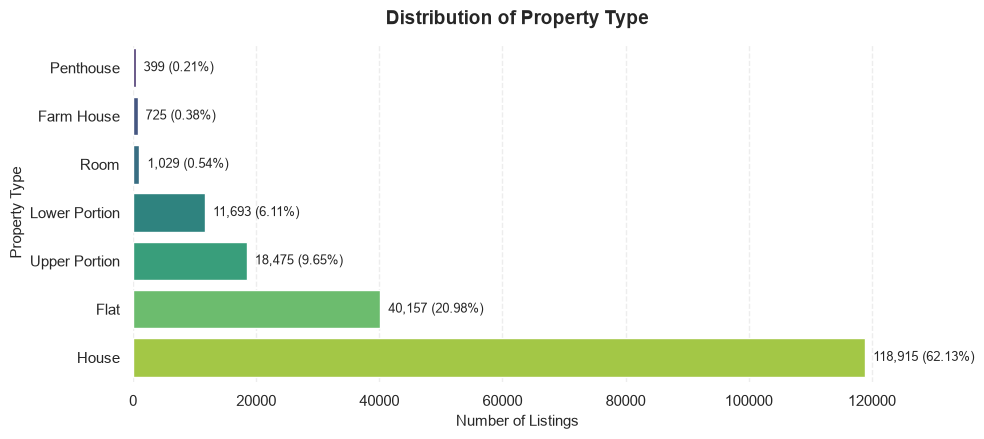

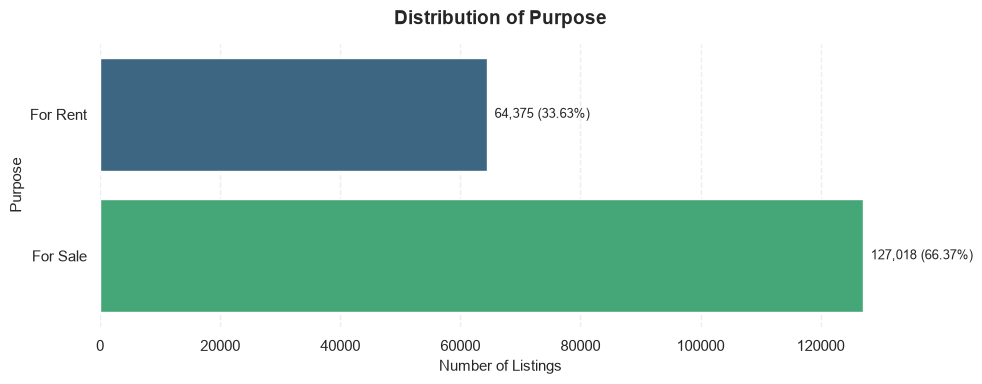

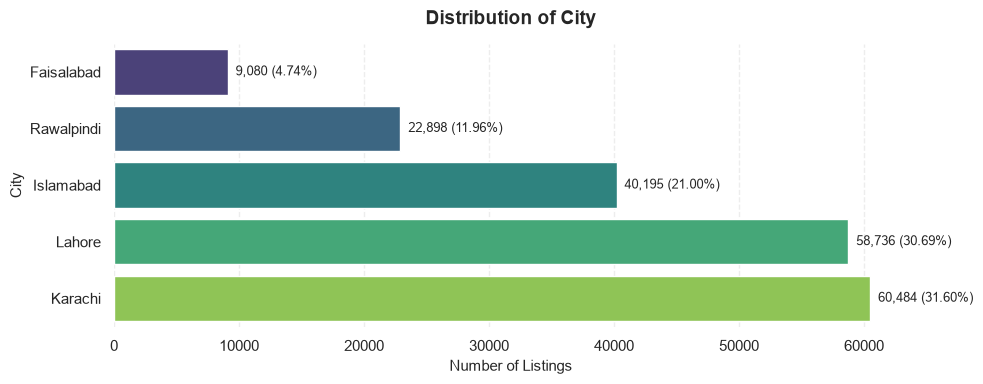

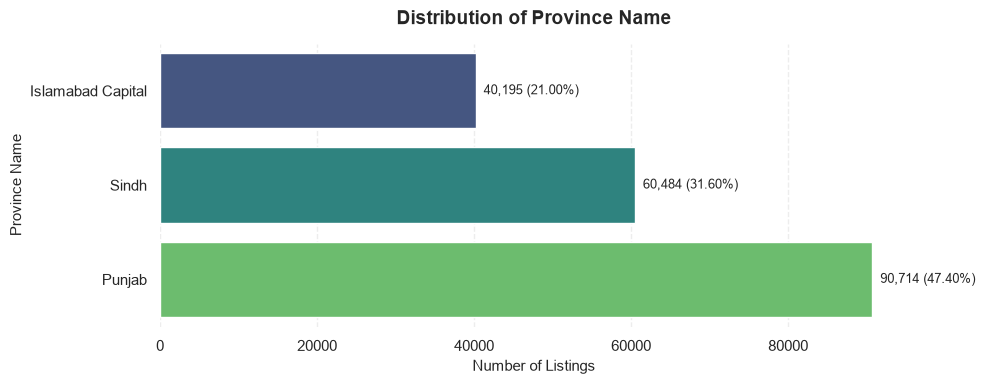

In [7]:


sns.set_theme(style="whitegrid", context="notebook")

for col in cat_cols:
    # Calculate count and percentage, including missing values
    counts = df[col].fillna("Missing").value_counts()
    
    plot_df = counts.rename_axis(col).reset_index(name="Count")
    plot_df["Percentage"] = (
        plot_df["Count"] / len(df) * 100
    )

    # Sort categories from largest to smallest
    plot_df = plot_df.sort_values("Count", ascending=True)

    # Create a distinct color for each category
    palette = sns.color_palette(
        "viridis", n_colors=len(plot_df)
    )

    # Plot
    fig, ax = plt.subplots(figsize=(10, max(4, len(plot_df) * 0.65)))

    sns.barplot(
        data=plot_df,
        x="Count",
        y=col,
        hue=col,
        palette=palette,
        legend=False,
        ax=ax
    )

    # Add count and percentage labels
    for bar, (_, row) in zip(ax.patches, plot_df.iterrows()):
        ax.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f'  {row["Count"]:,} ({row["Percentage"]:.2f}%)',
            va="center",
            fontsize=9
        )

    ax.set_title(
        f"Distribution of {col.replace('_', ' ').title()}",
        fontsize=14,
        fontweight="bold",
        pad=14
    )
    ax.set_xlabel("Number of Listings", fontsize=11)
    ax.set_ylabel(col.replace("_", " ").title(), fontsize=11)
    ax.ticklabel_format(axis="x", style="plain")
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.grid(axis="y", visible=False)

    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()


**Insights:**

- Houses account for about 62% of the listings.



- The dataset mixes sale and rental listings. Rental prices are not directly comparable to sale prices, so we should not combine them in our final sale-price prediction target.



- Karachi and Lahore have the largest listing counts, so the dataset is not evenly distributed across cities.



- Rare categories such as penthouses and farmhouses may still be important; low frequency alone is not a reason to remove them.

# Step 2: Data Cleaning 
*Investigate missing values, duplicates, inconsistent values, invalid measurements, and data types.*

From our initial inspection, we already know that `agency` and `agent` contain missing values, `area` stores measurements such as Marla and Kanal as text, and `price` ranges from 0 to 2 billion PKR.

**Step 2.1: Investigate Missing Values**

In [8]:
#Counting missing values in each column
missing_counts = df.isnull().sum()

#Calculating the percentage of missing values in each column
missing_percents = (missing_counts / len(df)) * 100


#Display only columns containing missing values
display(
    missing_counts[missing_counts > 0]
    .sort_values(ascending=False)
    .to_frame(name="Missing Values")
)

#Missing Values Summary
missing_summary = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage": missing_percents,
})

display(missing_summary)



,Missing Values
agent,47380
agency,47379


,Missing Count,Missing Percentage
property_id,0,0.000000
location_id,0,0.000000
page_url,0,0.000000
property_type,0,0.000000
price,0,0.000000
location,0,0.000000
city,0,0.000000
province_name,0,0.000000
latitude,0,0.000000
longitude,0,0.000000


**Insights:**

Our initial inspection identified these missing-value counts:

Feature	Missing values

`agency`:	47,379 (24.75%)
`agent`:	47,380 (24.75%)

Approximately one-quarter of the records lack agency and agent information.

The other 15 columns had no pandas-recognized missing values.

This means the missingness is concentrated in the `agency` and `agent` information. However, it does not yet tell us whether these values are missing in the same records or why the information is unavailable.

Diagnostic hack: Always compare the missing count with the total number of records. For example, 1,000 missing values may be insignificant in a dataset containing one million rows but substantial in a dataset containing 2,000 rows.

Decision: Because the missingness is substantial, we should investigate whether these features are useful enough to retain. We should not automatically delete them or their records.

In [9]:
#Identifying how many records are affected
# Two columns can have similar missing counts but may be missing in exactly the same rows—or in different rows. 
# This distinction affects our cleaning decision.

rows_with_missing = df.isnull().any(axis=1).sum() #count rows with atleast 1 missing

rows_without_missing = df.notnull().all(axis=1).sum() #count rows with no missing

print("Total Rows: ", len(df))
print("Rows with atleast 1 missing value: ", rows_with_missing)
print("Rows with no missing values: ", rows_without_missing)

# Also checking if both agent and agency are missing together
missing_pattern = (
    df[["agency", "agent"]]
    .isnull()
    .value_counts(ascending=False)
    .rename_axis(["Agency Missing", "Agent Missing"])
    .reset_index(name="Number of Rows")
)

display(missing_pattern)

Total Rows:  191393
Rows with atleast 1 missing value:  47380
Rows with no missing values:  144013


,Agency Missing,Agent Missing,Number of Rows
0,False,False,144013
1,True,True,47379
2,False,True,1


**Insights:**

This is a useful finding: agency and agent information are missing together in almost every affected record. It is unlikely that the two columns should be treated as independent missing-value problems.

For a future machine-learning pipeline, we can decide whether to exclude agency and agent as predictors, use an explicit missing category, or apply another suitable encoding. That decision belongs in feature selection and preprocessing, not in this initial investigation.

**Step 2.2 — Detect Hidden Missing Values and Inconsistent Data**

- `area` contains measurements stored as text, such as 5 Marla and 1 Kanal.
- `agency` and `agent` have approximately 24.76% missing values.
- Other columns show no recognized missing values, but that does not guarantee every value is valid.
- Values such as "?", " ", "Unknown", or "N/A" may not be detected by isnull().

Important: We will first identify suspicious values, then decide how to handle them. We will not replace every unusual value automatically.

In [10]:
#Search for hidden missing value markers

text_cols = df.select_dtypes(include=['object', 'str']).columns #selecting text columns only 

missing_tokens = ['?', "", "NA", "N/A", "na", "Unknown", "Not Available", "-", "--", "NULL", "NaN"] #deining hidden missing markers

for col in text_cols:
    values = df[col].dropna().astype(str).str.strip() #removing actual NA values (if any) and cleaning str by removing whitespaces

    matches = values[values.str.lower().isin([token.lower() for token in missing_tokens])]

    if not matches.empty:
        print(f'\n{col}:')
        print(matches.value_counts())

**Insights:**

The initial scan of your actual dataset found no exact matches for these common placeholders in the text columns.
That is useful, but it does not prove that all values are valid. Other unusual spellings or feature-specific problems can still exist.

Decision: Not replacing any values with NaN based on this check alone. We will investigate feature-specific inconsistencies next.

**Detect leading, trailing, and whitespace-only values**

A value such as "Masood Estate " contains a trailing space. Python may treat it as different from "Masood Estate", even though both refer to the same agency.

In [11]:
for col in text_cols:

    values = df[col].dropna().astype(str)

    whitespace_count = (
        values != values.str.strip()
    ).sum()

    if whitespace_count > 0:
        print(f"{col}: {whitespace_count} values with extra whitespaces")

# Display affected agency names
agency_values = df["agency"].dropna().astype(str)

display(
    agency_values[
        agency_values != agency_values.str.strip()
    ].value_counts()
)



agency: 32 values with extra whitespaces


agency
Masood Estate           31
AL Zafar Associates      1
Name: count, dtype: int64

In [12]:
#Cleaning whitespaces 

df_clean = df.copy() # making a copy

df_clean[text_cols] = df_clean[text_cols].apply(lambda col : col.str.strip())

df_clean['agency'].value_counts().head(10)

agency
Mash Allah Estate & Builders    821
Real Investment Consultants     794
Future Planners                 561
Lahore Grande Estate            463
Arham Estate                    429
Makkah Associates               410
Al Noor Estate Agency           395
Chaudhry Estate                 389
Al Qasim Estate Agency          375
Sagheer & Qadeer Associates     352
Name: count, dtype: int64

**Check categorical label consistency**

We need to confirm whether categorical columns contain variations in spelling, capitalization, or whitespace.

In [13]:
categorical_col = ["property_type", "city", "province_name", "purpose"]

display(df_clean[categorical_col].nunique())

for col in categorical_col:
    print(df_clean[col].value_counts(dropna=False))

property_type    7
city             5
province_name    3
purpose          2
dtype: int64

property_type
House            118915
Flat              40157
Upper Portion     18475
Lower Portion     11693
Room               1029
Farm House          725
Penthouse           399
Name: count, dtype: int64
city
Karachi       60484
Lahore        58736
Islamabad     40195
Rawalpindi    22898
Faisalabad     9080
Name: count, dtype: int64
province_name
Punjab               90714
Sindh                60484
Islamabad Capital    40195
Name: count, dtype: int64
purpose
For Sale    127018
For Rent     64375
Name: count, dtype: int64


**Insights:**

Your categorical columns currently show:

| Feature | Unique Categories | Observed Values |
|---|---:|---|
| property_type | 7 | House, Flat, Upper Portion, Lower Portion, Room, Farm House, Penthouse |
| city | 5 | Karachi, Lahore, Islamabad, Rawalpindi, Faisalabad |
| province_name | 3 | Punjab, Sindh, Islamabad Capital |
| purpose | 2 | For Sale, For Rent |


The initial inspection found no leading/trailing whitespace or capitalization variants in these four columns.

Diagnostic hack: If you expect a column to have two categories but discover values such as "For Sale", "for sale", and "For Sale ", investigate whether they are inconsistent representations of the same category.

Decision: No label correction is currently indicated for these four columns. We will recheck categorical values if later investigations reveal anomalies.

**Convert date_added to datetime**

Our earlier inspection found dates such as 07-17-2019 and 10-06-2018. Because 07-17-2019 cannot be interpreted as month-day-year if the day and month are reversed, the evidence supports the format MM-DD-YYYY.
We can convert the column using that explicit format rather than relying on automatic date inference.

In [14]:
parsed_date = pd.to_datetime(
    df_clean['date_added'],
    format="%m-%d-%Y",
    errors='coerce'
)

df_clean['date_added'] = parsed_date

print("missing: ", df_clean['date_added'].isna().sum())
print("dtype: ", df_clean['date_added'].dtype)
df_clean['date_added'].sample(5, random_state=42)

missing:  0
dtype:  datetime64[us]


63008    2019-05-05
154887   2019-07-11
105420   2019-06-28
56748    2019-04-06
182726   2019-07-20
Name: date_added, dtype: datetime64[us]

**Create a Numerical area feature into square feet**

The original area column contains measurements such as 5 Marla and 1 Kanal. We should convert these into one numeric unit so that area can be used in statistical analysis and regression.
For this project, we will use the following assumptions:
- 1 Marla = 225 square feet
- 1 Kanal = 20 Marla = 4,500 square feet

Keep `area` as the original text column.

In [15]:
area_text = df_clean['area'].astype("string").str.strip() #removing whitespaces

area_text = area_text.str.replace(",", "", regex=False) #removing commas in it

area_parts = area_text.str.extract(r"^(\d+(?:\.\d+)?)\s*(Marla|Kanal)$", flags=0) # extract numeric value

area_value = pd.to_numeric(area_parts[0], errors="coerce") #getting area value

area_unit = area_parts[1].str.lower() #converting in lowercase

df_clean['area_sqft'] = np.select( #creating a new col for area sq-ft

    [
        area_unit.eq("marla"),
        area_unit.eq("kanal")
    ],
    [
        area_value * 225,
        area_value * 20 * 225
    ],

    default=np.nan
)

display(df_clean[['area', 'area_sqft']].sample(10, random_state=42))

print("Original missing area values:", df_clean["area"].isna().sum())
print("Zero area records: ", df_clean['area'].eq("0").sum())
print("Areas that could not be parsed:", df_clean["area_sqft"].isna().sum())

display(df_clean["area_sqft"].describe())


,area,area_sqft
63008,7.5 Marla,1687.5
154887,1.3 Kanal,5850.0
105420,6 Marla,1350.0
56748,3.1 Marla,697.5
182726,5 Marla,1125.0
93249,6 Marla,1350.0
98642,8 Marla,1800.0
175579,2.5 Marla,562.5
150019,1 Kanal,4500.0
122162,4 Marla,900.0


Original missing area values: 0
Zero area records:  0
Areas that could not be parsed: 0


count    1.913930e+05
mean     3.279044e+03
std      9.975223e+04
min      0.000000e+00
25%      1.102500e+03
50%      1.710000e+03
75%      2.700000e+03
max      2.799990e+07
Name: area_sqft, dtype: float64

**Findings:**

| Original Area | Area_sqft |
|---|---:|
| 5 Marla | 1,125 |
| 10 Marla | 2,250 |
| 1 Kanal | 4,500 |
| 2 Kanal | 9,000 |

This creates the derived feature, but does not prove that every source area is correct. The eight comma-containing records below remain flagged for review.

**Flag suspicious measurements**

Our earlier investigation identified eight rows with comma-separated, unusually large measurements, including 1,000 Kanal and 4,500 Kanal.
The conversion code can parse these values, but successful conversion does not establish that the measurements are valid.

In [16]:
suspicious_area_mask = (
    df_clean["area"].astype("string").str.contains(",", na=False)
)
print("Suspicious Areas count: ", suspicious_area_mask.sum())
display(
    df_clean.loc[
        suspicious_area_mask,
        ["area", "area_sqft", "price", "city", "property_type"]
    ]
)

zero_area_mask = (
    df_clean["area_sqft"].eq(0)
)

print("Zero Area counts: ", zero_area_mask.sum())

display(
    df_clean.loc[
        zero_area_mask,
        ["area", "area_sqft", "price", "city", "property_type"]
    ].head()
)

Suspicious Areas count:  8


,area,area_sqft,price,city,property_type
103756,"4,450 Kanal",20025000.0,42500000,Lahore,House
133378,"4,500 Kanal",20250000.0,35000000,Lahore,House
154284,"2,250 Kanal",10125000.0,22000000,Rawalpindi,House
155217,"1,000 Kanal",4500000.0,5000000,Islamabad,Flat
155242,"1,722.2 Kanal",7749900.0,4000000,Islamabad,Flat
171265,"1,000 Kanal",4500000.0,300000,Islamabad,House
172128,"1,175 Kanal",5287500.0,23500,Lahore,Lower Portion
172809,"6,222.2 Kanal",27999900.0,27500000,Islamabad,House


Zero Area counts:  16


,area,area_sqft,price,city,property_type
30586,0 Marla,0.0,4400000,Karachi,House
39658,0 Marla,0.0,12500000,Lahore,House
122309,0 Marla,0.0,18000000,Lahore,House
135871,0 Marla,0.0,16500000,Islamabad,House
138049,0 Marla,0.0,2200000,Lahore,House


**Findings:**

Actual finding: 8 rows fail the expected format check. The comma may be a thousands separator, or it may indicate a data-entry error. We should not silently assume which interpretation is correct.
We’ll preserve the original area text and flag these records for review. We can create a separate numerical area feature while retaining traceability to the original values.

In [17]:
# Preserve explicit review flags
df_clean["area_format_flag"] = suspicious_area_mask

df_clean["are_zero_flag"] = zero_area_mask

display(df_clean.loc[suspicious_area_mask].head())

display(df_clean.loc[zero_area_mask].head())


,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent,area_sqft,area_format_flag,are_zero_flag
103756,16873061,3555,https://www.zameen.com/Property/lahore_askari_...,House,42500000,Askari,Lahore,Punjab,31.536408,74.416038,4,"4,450 Kanal",For Sale,4,2019-06-26,Best Residency Provider,Imran Rana,20025000.0,True,False
133378,17086430,4170,https://www.zameen.com/Property/sabzazar_schem...,House,35000000,Sabzazar Scheme,Lahore,Punjab,31.523459,74.265332,3,"4,500 Kanal",For Sale,3,2019-07-03,Nadeem Estate,Muhammad Sohail Sultan,20250000.0,True,False
154284,17232174,3047,https://www.zameen.com/Property/bahria_town_ra...,House,22000000,Bahria Town Rawalpindi,Rawalpindi,Punjab,33.531952,73.115211,7,"2,250 Kanal",For Sale,5,2019-07-11,SK Marketing Property Advisor & Builders,SK Marketing,10125000.0,True,False
155217,17239321,11439,https://www.zameen.com/Property/islamabad_thal...,Flat,5000000,Thalian,Islamabad,Islamabad Capital,33.540213,72.911273,0,"1,000 Kanal",For Sale,0,2019-07-11,Awan Real Estate,Raja waseem ahmed,4500000.0,True,False
155242,17240193,764,https://www.zameen.com/Property/islamabad_g_15...,Flat,4000000,G-15,Islamabad,Islamabad Capital,33.631486,72.926559,2,"1,722.2 Kanal",For Sale,2,2019-07-11,Land Point Marketing Pvt Ltd,Adnan,7749900.0,True,False


,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent,area_sqft,area_format_flag,are_zero_flag
30586,13935017,476,https://www.zameen.com/Property/karachi_malir_...,House,4400000,Malir,Karachi,Sindh,24.893209,67.195473,2,0 Marla,For Sale,2,2019-05-05,Infinity Properties,Shehzad,0.0,False,True
39658,14619957,3965,https://www.zameen.com/Property/johar_town_pha...,House,12500000,Johar Town,Lahore,Punjab,31.474097,74.263802,5,0 Marla,For Sale,5,2019-06-11,Siddique Associates & Builders,Hamza Malik,0.0,False,True
122309,17028927,93,https://www.zameen.com/Property/lahore_johar_t...,House,18000000,Johar Town,Lahore,Punjab,31.462347,74.293642,3,0 Marla,For Sale,3,2019-07-01,Saqib Estate & Builders,Malik Saqib Rafiq,0.0,False,True
135871,17095118,173,https://www.zameen.com/Property/islamabad_i_10...,House,16500000,I-10,Islamabad,Islamabad Capital,33.648922,73.038969,4,0 Marla,For Sale,5,2019-07-03,Seven Star Enterprises,Ch Ahsan,0.0,False,True
138049,17108764,11657,https://www.zameen.com/Property/lahore_katar_b...,House,2200000,Katar Bund Road,Lahore,Punjab,31.474503,74.231476,2,0 Marla,For Sale,2,2019-07-04,Al Karam Estate Advisor,Ishfaq Jutt,0.0,False,True


**Validate the standardized area**

In [18]:
display(df_clean['area_sqft'].describe())

print("Zero values: ", df_clean['area_sqft'].eq(0).sum())

count    1.913930e+05
mean     3.279044e+03
std      9.975223e+04
min      0.000000e+00
25%      1.102500e+03
50%      1.710000e+03
75%      2.700000e+03
max      2.799990e+07
Name: area_sqft, dtype: float64

Zero values:  16


**Verify the overall result**

In [19]:
print("Original dataset shape:", df_raw.shape)
print("Cleaned dataset shape:", df_clean.shape) #new col area_sqft added

print("\nMissing values in cleaned dataset:")
display(
    df_clean.isna().sum().loc[lambda s: s>0].to_frame("Missing Values")
)

print("\nNew area feature:")
print("Area per sqft dtype: ", df_clean['area_sqft'].dtype)
print("Successfull parsed areas: ", df_clean['area_sqft'].notna().sum())

Original dataset shape: (191393, 17)
Cleaned dataset shape: (191393, 20)

Missing values in cleaned dataset:


,Missing Values
agency,47379
agent,47380



New area feature:
Area per sqft dtype:  float64
Successfull parsed areas:  191393


**Step 2.3: Investigate and handle duplicate records**

*We will check duplicates first, remove them only when the evidence justifies it, and verify the result. We will not modify*`df_raw`.

**Check for completely identical rows**

In [20]:
duplicated_rows = df_clean.duplicated() #counting duplicated rows

print("Total Duplicated rows: ", duplicated_rows.sum())
print("Percentage of Dataset: ", round(duplicated_rows.mean() * 100, 4), "%")

# checking for individual columns for duplications
prop_id_dup = df_clean["property_id"].duplicated(keep='first')

display(
    df_clean.loc[prop_id_dup].sort_values("property_id")
)

print("Duplicated IDs: ", df_clean['property_id'].duplicated().sum())
print("Total Duplicated URLS: ", df_clean['page_url'].duplicated().sum())
print("Missing page URLs:", df_clean["page_url"].isna().sum())



Total Duplicated rows:  0
Percentage of Dataset:  0.0 %


,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent,area_sqft,area_format_flag,are_zero_flag


Duplicated IDs:  0
Total Duplicated URLS:  0
Missing page URLs: 0


Didn't find any duplicated values

**Investigate listings with identical characteristics**

Two different listings may have the same property type, price, location, area, number of bedrooms, and bathrooms. This does not necessarily mean they are duplicates: properties in the same development can share those characteristics.
Let's investigate this pattern without deleting anything.

In [21]:
listing_features = [
    "property_type",
    "price",
    "location",
    "city",
    "province_name",
    "area",
    "purpose",
    "bedrooms",
    "baths",
    "date_added"
]

similar_listing_mask = df_clean.duplicated(subset=listing_features, keep=False)

print("Rows sharing identical listing characteristics:",
      similar_listing_mask.sum())

print("Repeated rows after the first:",
      df_clean.duplicated(
          subset=listing_features,
          keep="first"
      ).sum())

display(
    df_clean.loc[
        similar_listing_mask,
        listing_features + ["property_id", "page_url"]
    ].head(10)
)

Rows sharing identical listing characteristics: 49306
Repeated rows after the first: 31487


,property_type,price,location,city,province_name,area,purpose,bedrooms,baths,date_added,property_id,page_url
15,House,23500000,Askari,Lahore,Punjab,10 Marla,For Sale,4,4,2019-06-18,1794392,https://www.zameen.com/Property/askari_10_aska...
25,House,23000000,Askari,Lahore,Punjab,10 Marla,For Sale,4,5,2019-06-18,2439775,https://www.zameen.com/Property/askari_10_aska...
26,House,21500000,Askari,Lahore,Punjab,10 Marla,For Sale,4,5,2019-06-18,2439785,https://www.zameen.com/Property/askari_10_aska...
27,House,21500000,Askari,Lahore,Punjab,10 Marla,For Sale,4,5,2019-06-18,2439790,https://www.zameen.com/Property/askari_10_aska...
31,House,23000000,Askari,Lahore,Punjab,10 Marla,For Sale,4,5,2019-06-18,2510625,https://www.zameen.com/Property/askari_10_aska...
36,House,50000000,Gulberg,Lahore,Punjab,1 Kanal,For Sale,5,6,2019-07-03,2821111,https://www.zameen.com/Property/gulberg_zafar_...
50,House,17500000,Bahria Town,Lahore,Punjab,10 Marla,For Sale,5,6,2019-05-03,3892037,https://www.zameen.com/Property/bahria_town_ba...
52,House,22000000,Askari,Lahore,Punjab,10 Marla,For Sale,4,5,2019-06-18,3931998,https://www.zameen.com/Property/askari_10_aska...
53,House,23500000,Askari,Lahore,Punjab,10 Marla,For Sale,5,6,2019-06-18,3932053,https://www.zameen.com/Property/askari_10_aska...
54,House,41500000,Askari,Lahore,Punjab,1 Kanal,For Sale,5,6,2019-06-18,3932098,https://www.zameen.com/Property/askari_10_aska...


**Insights:**

49,306 rows belong to groups sharing identical values across these selected characteristics; 31,487 are repeated occurrences after the first row within those groups.
These are potentially similar listings, not confirmed duplicates. We should not delete them based on these columns alone.


**Verify that the dataset's row count remains unchanged:**

In [22]:
print("Original row count:", len(df_raw))
print("Current cleaned row count:", len(df_clean))
print("Rows removed in Step 2.3:", len(df_raw) - len(df_clean))

Original row count: 191393
Current cleaned row count: 191393
Rows removed in Step 2.3: 0


**Step 2.4: Validate values and correct clear data problems**

We will investigate:
1. Numeric columns and their data types.
2. Price values, especially zero and negative prices.
3. Bedrooms and bathrooms, including zero values.
4. Area measurements that are unusually large or could not be parsed.
5. Date formatting and conversion.

In [23]:
numeric_cols = [
    "price",
    "latitude",
    "longitude",
    "bedrooms",
    "baths",
    "area_sqft"
]

display(df_clean[numeric_cols].dtypes.to_frame("Data Type"))

,Data Type
price,int64
latitude,float64
longitude,float64
bedrooms,int64
baths,int64
area_sqft,float64


**Validate the price column**

initial analysis found that price ranges from 0 to 2,000,000,000 PKR, with a median of 7,300,000 PKR. The minimum of zero needs investigation, but the maximum should not automatically be considered an error.

In [24]:
print("Zeros in price column: ", df_clean['price'].eq(0).sum())

display(df_clean['price'].describe().to_frame("Price (PKR)"))

display(
    df_clean.loc[
        df_clean["price"].le(0),
        ["property_id", "property_type", "price", "area",
         "city", "purpose", "date_added"]
    ].head(20)
)

total_percent_missing_price = df_clean['price'].eq(0).sum() * 100 / df_clean['price'].value_counts().sum()
print("Total Prices missing percentage: ", round(total_percent_missing_price, 4), "%")

Zeros in price column:  3


,Price (PKR)
count,1.913930e+05
mean,1.644655e+07
std,3.416412e+07
min,0.000000e+00
25%,8.000000e+04
50%,7.300000e+06
75%,1.800000e+07
max,2.000000e+09


,property_id,property_type,price,area,city,purpose,date_added
70880,16081186,House,0,5 Marla,Rawalpindi,For Rent,2019-05-06
97464,16786134,Farm House,0,8 Kanal,Karachi,For Sale,2019-06-21
140353,17122202,House,0,10 Marla,Rawalpindi,For Sale,2019-07-05


Total Prices missing percentage:  0.0016 %


**Findings:**

- 3 listings have a `price` of zero (0.0016%).
- 0 listings have a negative `price`.
- The zero-price records include both sale and rental listings.

A price of zero is not a usable numeric target for a price-prediction model. We will remove those three records from the working dataset, while keeping them intact in df_raw.

In [25]:
rows_before = len(df_clean)

df_clean = df_clean.loc[df_clean['price'] > 0]

rows_removed = rows_before - len(df_clean)

print("Rows removed:", rows_removed)
print("Rows remaining:", len(df_clean))
print("Zero prices remaining:", df_clean["price"].eq(0).sum())
print("Original dataset preserved:", len(df_raw))


Rows removed: 3
Rows remaining: 191390
Zero prices remaining: 0
Original dataset preserved: 191393


**Validate bedrooms and bathrooms**

- The original dataset stores `bedrooms` and `baths` as numeric types.
- Investigate zero and extreme room counts




In [26]:
for col in ["bedrooms", "baths"]:
    print(f"\n{col}")
    print("Data type:", df_clean[col].dtype)
    print("Unique values:", df_clean[col].nunique())
    print("Zeros: ", df_clean[col].eq(0).sum())


df_clean.value_counts(subset=["bedrooms", "baths"], dropna=False).sort_index().reset_index(name="count")

df_clean[["bedrooms", "baths"]].describe()



bedrooms
Data type: int64
Unique values: 24
Zeros:  24956

baths
Data type: int64
Unique values: 17
Zeros:  48127


,bedrooms,baths
count,191390.000000,191390.000000
mean,3.171566,2.866001
std,1.952378,2.435325
min,0.000000,0.000000
25%,2.000000,0.000000
50%,3.000000,3.000000
75%,4.000000,4.000000
max,68.000000,403.000000


In [27]:
#Checking maximum listing of bathroom

extreme_baths = df_clean['baths'] > 15

display(
    df_clean.loc[
        extreme_baths,
        ["property_id", "property_type", "price", "city", "area",
         "purpose", "bedrooms", "baths"]
    ]
)

,property_id,property_type,price,city,area,purpose,bedrooms,baths
136735,17101832,House,15000000,Rawalpindi,5 Marla,For Sale,6,403


After confirming the anomalous record, set its baths value to missing rather than inventing a corrected number:

In [28]:
df_clean.loc[extreme_baths, "baths"] = np.nan

A listing reports 68 bedrooms, but it is a large rental property. That value is suspicious, yet the available fields do not prove the correct number. Flag it for review rather than automatically changing or deleting it.

**Findings:**

The dataset contains many zero values: approximately 24,959 zero-bedroom records and 48,130 zero-bathroom records before removing the three zero-price listings. These could represent missing or unreported information, or special listing types. We should not automatically turn every zero into a missing value without further context.
One record reports 403 bathrooms for a 5-Marla house. That is an obvious implausible value for this listing and should be treated as an invalid observation, not capped to an arbitrary maximum.



Keep the original `area` values and investigate suspicious records. Do not cap, correct, or delete them based on size alone.



**Step 2.5: Investigate potential outliers**

We will investigate four areas:

1. price — the target variable.
2. Area_sqft — property size.
3. bedrooms and baths — unusually high or low counts.
4. The relationship between price and area — to identify records that deserve closer inspection.

We will flag and investigate first, not automatically delete or cap values. Since you have already decided to exclude zero-price records, perform this analysis on your current df_clean, where those records have been removed.

**Inspect the price distribution**

In [29]:
#Starting with descriptive statistics and percentiles

price_percentiles = df_clean['price'].quantile([0.00, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00])

display(
    price_percentiles.to_frame("Price (PKR)")
)

,Price (PKR)
0.00,1.000000e+00
0.01,1.400000e+04
0.05,2.300000e+04
0.25,8.000000e+04
0.50,7.300000e+06
0.75,1.800000e+07
0.95,6.200000e+07
0.99,1.550000e+08
1.00,2.000000e+09


the median describes the middle listing, while the 95th and 99th percentiles help us understand the upper tail. Comparing these with the maximum helps reveal how extreme the largest prices are.

Visualize the distribution using a histogram and box plot:

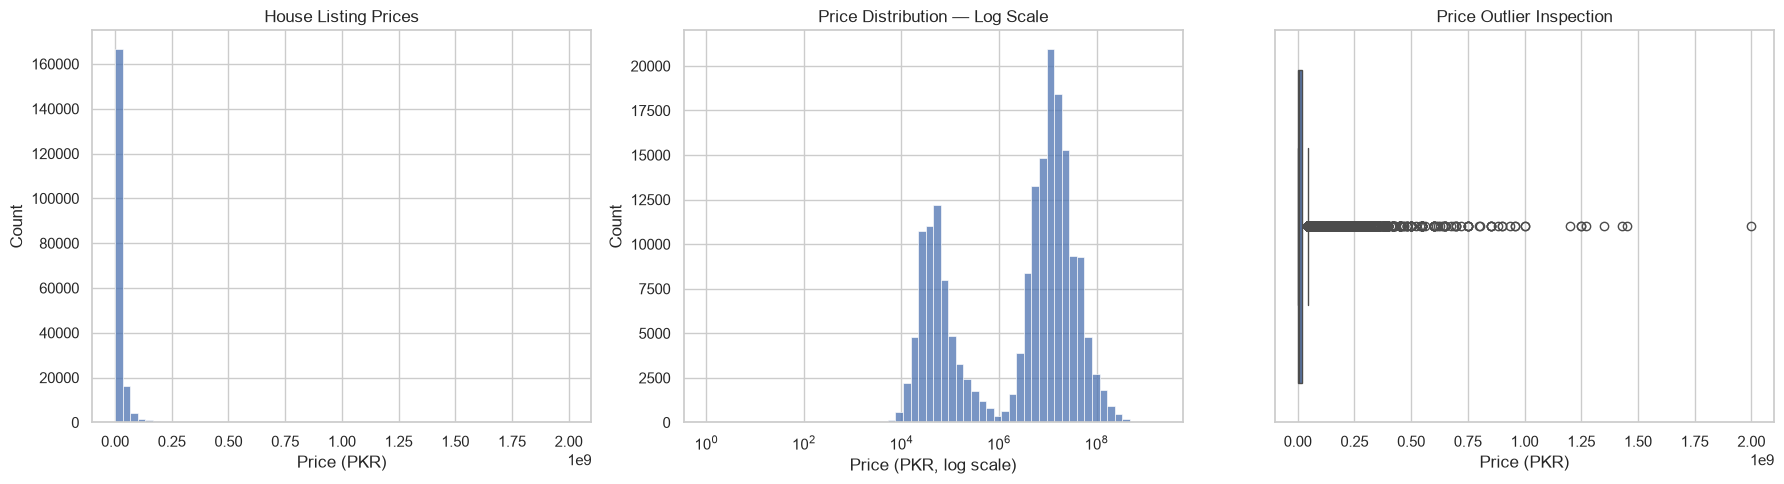

In [30]:


sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Price distribution on the original scale
sns.histplot(
    data=df_clean,
    x="price",
    bins=60,
    ax=axes[0]
)
axes[0].set_title("House Listing Prices")
axes[0].set_xlabel("Price (PKR)")

# 2. Price distribution on a logarithmic x-axis
sns.histplot(
    data=df_clean,
    x="price",
    bins=60,
    log_scale=True,
    ax=axes[1]
)
axes[1].set_title("Price Distribution — Log Scale")
axes[1].set_xlabel("Price (PKR, log scale)")

# 3. Box plot
sns.boxplot(
    data=df_clean,
    x="price",
    ax=axes[2]
)
axes[2].set_title("Price Outlier Inspection")
axes[2].set_xlabel("Price (PKR)")

plt.tight_layout()
plt.show()

A long tail to the right indicates that a small number of listings have much higher prices than most listings.



Points beyond the box plot's whiskers are potential outliers, not necessarily incorrect data.



If most prices are compressed near zero on the graph, a logarithmic scale may help us inspect the distribution more clearly

**Detect price outliers using the IQR method**

In [31]:
Q1 = df_clean['price'].quantile(0.25)
Q3 = df_clean['price'].quantile(0.75)

IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

price_outlier_mask = (
    (df_clean['price'] < lower_fence) |
    (df_clean['price'] > upper_fence)
)

print("Q1: ", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)
print("Potential price outliers:", price_outlier_mask.sum())
print(
    "Percentage flagged:",
    round(price_outlier_mask.mean() * 100, 2), "%"
)


Q1:  80000.0
Q3: 18000000.0
IQR: 17920000.0
Lower fence: -26800000.0
Upper fence: 44880000.0
Potential price outliers: 16818
Percentage flagged: 8.79 %


In [32]:
#Inspect highest price listing in dataset
display(
    df_clean.loc[
        price_outlier_mask,
        ["property_id", "property_type", "price", "area",
         "area_sqft", "city", "location", "purpose",
         "bedrooms", "baths"]
    ]
    .sort_values("price", ascending=False)
    .head(20)
)

,property_id,property_type,price,area,area_sqft,city,location,purpose,bedrooms,baths
90714,16683907,House,2000000000,19.2 Kanal,86400.0,Lahore,Mall Road,For Sale,11,10.0
61464,15749804,House,1450000000,6.1 Kanal,27450.0,Karachi,KDA Scheme 1,For Sale,8,8.0
72863,16163317,House,1430000000,13 Kanal,58500.0,Lahore,Gulberg,For Sale,8,9.0
81652,16444819,House,1350000000,6 Kanal,27000.0,Karachi,KDA Scheme 1,For Sale,5,6.0
15564,12112778,House,1270000000,6.4 Kanal,28800.0,Lahore,Gulberg,For Sale,0,0.0
78587,16346416,House,1250000000,8 Kanal,36000.0,Lahore,Gulberg,For Sale,0,0.0
39,3217881,House,1250000000,8 Kanal,36000.0,Lahore,Gulberg,For Sale,0,0.0
90,4536854,House,1200000000,8 Kanal,36000.0,Lahore,Gulberg,For Sale,0,0.0
58573,15630212,House,1000000000,4 Kanal,18000.0,Karachi,Clifton,For Sale,11,10.0
101184,16845674,House,1000000000,9 Kanal,40500.0,Lahore,Gulberg,For Sale,8,0.0


**Findings:**

| Statistic | Result |
|---|---:|
| Q1 (25th Percentile) | PKR 80,000 |
| Median (50th Percentile) | PKR 7,300,000 |
| Q3 (75th Percentile) | PKR 18,000,000 |
| IQR | PKR 17,920,000 |
| Lower Fence | PKR −26,800,000 |
| Upper Fence | PKR 44,880,000 |
| Prices Above Upper Fence | 16,818 |

The lower fence is negative, so it does not identify any remaining low-price outliers. The upper fence flags about 8.8% of listings.

Decision: do not delete or cap all 16,818 high-price listings. The dataset contains different property types and cities, so a single threshold can flag legitimate expensive properties as outliers. We’ll inspect the relevant house-for-sale subset and use domain context to distinguish suspicious values from plausible extremes.

**Flag suspicious small positive prices**


In [33]:
df_clean["price_review_flag"] = df_clean["price"].between(1, 8)

print("Total Small postive prices: ", df_clean['price_review_flag'].sum())

display(
    df_clean.loc[
        (df_clean["purpose"] == "For Sale") &
        df_clean["price_review_flag"],
        ["property_id", "property_type", "price", "price_review_flag", "city", "area", "purpose"]
    ]
)

Total Small postive prices:  17


,property_id,property_type,price,price_review_flag,city,area,purpose
10013,11077891,House,1,True,Lahore,5 Marla,For Sale
10014,11078343,House,4,True,Lahore,1 Kanal,For Sale
25543,13357143,House,5,True,Karachi,12 Marla,For Sale
27718,13656316,House,6,True,Karachi,6 Marla,For Sale
28527,13686015,House,8,True,Karachi,1 Kanal,For Sale
36961,14431910,House,4,True,Karachi,15 Marla,For Sale
78718,16339390,House,1,True,Karachi,1 Kanal,For Sale
108958,16919078,House,3,True,Rawalpindi,12 Marla,For Sale
165134,17295163,House,1,True,Karachi,4.8 Marla,For Sale
165404,17295759,House,1,True,Rawalpindi,10 Marla,For Sale


The dataset has 17 for-sale listings priced between PKR 1 and PKR 8. These are almost certainly unusable as real listing prices, but we should keep a visible flag so the exclusion is documented when we create the modeling subset.

**Investigate property-area outliers**

Property size can contain errors too. In Step 2.2, we identified eight area strings with commas, such as 1,000 Kanal. These need particular attention because interpreting them literally could produce extraordinarily large square-foot values.

First, inspect those original records:

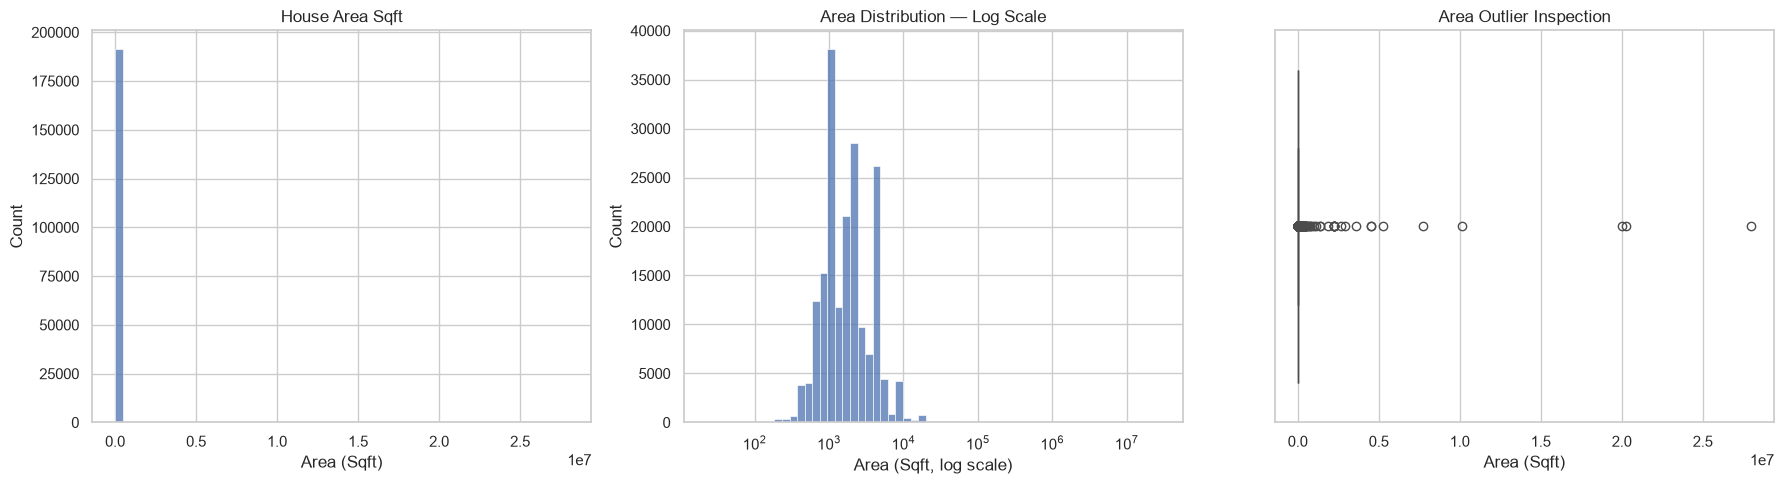

In [34]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Price distribution on the original scale
sns.histplot(
    data=df_clean,
    x="area_sqft",
    bins=60,
    ax=axes[0]
)
axes[0].set_title("House Area Sqft")
axes[0].set_xlabel("Area (Sqft)")

# 2. Price distribution on a logarithmic x-axis
sns.histplot(
    data=df_clean,
    x="area_sqft",
    bins=60,
    log_scale=True,
    ax=axes[1]
)
axes[1].set_title("Area Distribution — Log Scale")
axes[1].set_xlabel("Area (Sqft, log scale)")

# 3. Box plot
sns.boxplot(
    data=df_clean,
    x="area_sqft",
    ax=axes[2]
)
axes[2].set_title("Area Outlier Inspection")
axes[2].set_xlabel("Area (Sqft)")

plt.tight_layout()
plt.show()

In [35]:
Q1_area = df_clean['area_sqft'].quantile(0.25)
Q3_area = df_clean['area_sqft'].quantile(0.75)

IQR_area = Q3_area - Q1_area

lower_area_fence = Q1_area - 1.5 * IQR_area
upper_area_fence = Q3_area + 1.5 * IQR_area

area_outlier_mask = (
    (df_clean["area_sqft"] < lower_area_fence) |
    (df_clean["area_sqft"] > upper_area_fence)
)

print("Lower area fence:", lower_area_fence)
print("Upper area fence:", upper_area_fence)
print("Potential area outliers:", area_outlier_mask.sum())

display(
    df_clean.loc[
        area_outlier_mask,
        ["property_id", "area", "area_sqft", "price",
         "city", "property_type", "purpose"]
    ]
    .sort_values("area_sqft", ascending=False)
    .head(20)
)

Lower area fence: -1293.75
Upper area fence: 5096.25
Potential area outliers: 11060


,property_id,area,area_sqft,price,city,property_type,purpose
172809,17323550,"6,222.2 Kanal",27999900.0,27500000,Islamabad,House,For Sale
133378,17086430,"4,500 Kanal",20250000.0,35000000,Lahore,House,For Sale
103756,16873061,"4,450 Kanal",20025000.0,42500000,Lahore,House,For Sale
154284,17232174,"2,250 Kanal",10125000.0,22000000,Rawalpindi,House,For Sale
155242,17240193,"1,722.2 Kanal",7749900.0,4000000,Islamabad,Flat,For Sale
172128,17322561,"1,175 Kanal",5287500.0,23500,Lahore,Lower Portion,For Rent
155217,17239321,"1,000 Kanal",4500000.0,5000000,Islamabad,Flat,For Sale
171265,17315237,"1,000 Kanal",4500000.0,300000,Islamabad,House,For Rent
176036,17336074,800 Kanal,3600000.0,16000,Rawalpindi,Flat,For Rent
134235,17087885,650 Kanal,2925000.0,13000,Rawalpindi,Lower Portion,For Rent


**Flag unusually large areas**

In [36]:
display(
    df_clean.loc[
        df_clean["area_format_flag"],
        ["property_id", "property_type", "price", "city", "area",
         "area_sqft", "purpose"]
    ]
)

,property_id,property_type,price,city,area,area_sqft,purpose
103756,16873061,House,42500000,Lahore,"4,450 Kanal",20025000.0,For Sale
133378,17086430,House,35000000,Lahore,"4,500 Kanal",20250000.0,For Sale
154284,17232174,House,22000000,Rawalpindi,"2,250 Kanal",10125000.0,For Sale
155217,17239321,Flat,5000000,Islamabad,"1,000 Kanal",4500000.0,For Sale
155242,17240193,Flat,4000000,Islamabad,"1,722.2 Kanal",7749900.0,For Sale
171265,17315237,House,300000,Islamabad,"1,000 Kanal",4500000.0,For Rent
172128,17322561,Lower Portion,23500,Lahore,"1,175 Kanal",5287500.0,For Rent
172809,17323550,House,27500000,Islamabad,"6,222.2 Kanal",27999900.0,For Sale


**Findings:**

There are eight comma-formatted area records and 16 zero-area records in the original data. The comma-formatted records can be parsed numerically after removing commas, but their meaning is not verified. Zero-area records are not valid measurements.
Decision: retain these records for review, but do not use their questionable area measurements as valid numeric features without further validation.

In [37]:
df_clean[["bedrooms", "baths"]].describe()

,bedrooms,baths
count,191390.000000,191389.000000
mean,3.171566,2.863911
std,1.952378,2.257050
min,0.000000,0.000000
25%,2.000000,0.000000
50%,3.000000,3.000000
75%,4.000000,4.000000
max,68.000000,15.000000


In [38]:


for col in ["bedrooms", "baths"]:
    print(f"\n{col} — descriptive statistics")
    display(df_clean[col].describe().to_frame())

    print(f"Highest values in {col}:")
    display(df_clean[col].value_counts().sort_index().tail(10))


bedrooms — descriptive statistics


,bedrooms
count,191390.000000
mean,3.171566
std,1.952378
min,0.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,68.000000


Highest values in bedrooms:


bedrooms
14    8
15    8
16    4
18    2
20    2
21    1
25    4
27    2
28    4
68    1
Name: count, dtype: int64


baths — descriptive statistics


,baths
count,191389.000000
mean,2.863911
std,2.257050
min,0.000000
25%,0.000000
50%,3.000000
75%,4.000000
max,15.000000


Highest values in baths:


baths
6.0     18796
7.0      5989
8.0      2205
9.0       763
10.0      983
11.0        7
12.0       10
13.0        3
14.0        3
15.0        1
Name: count, dtype: int64

In [39]:
display(
    df_clean.loc[
        (df_clean["bedrooms"] > 15) |
        (df_clean["baths"] > 15),
        ["property_id", "property_type", "price", "area",
         "area_sqft", "bedrooms", "baths", "city", "location"]
    ].sort_values(["bedrooms", "baths"], ascending=False).head(10)
)

print("Missing is Baths: ", df_clean['baths'].isna().sum())

,property_id,property_type,price,area,area_sqft,bedrooms,baths,city,location
148853,17197397,House,2500000,6.6 Kanal,29700.0,68,0.0,Karachi,North Nazimabad
127702,17053936,House,1300000,2 Kanal,9000.0,28,0.0,Rawalpindi,Satellite Town
148120,17187235,House,1300000,2 Kanal,9000.0,28,0.0,Rawalpindi,Satellite Town
175087,17333041,House,1300000,2 Kanal,9000.0,28,0.0,Rawalpindi,Satellite Town
175088,17333042,House,1300000,2 Kanal,9000.0,28,0.0,Rawalpindi,Satellite Town
153405,17227364,House,80000000,3 Kanal,13500.0,27,0.0,Rawalpindi,Gulraiz Housing Scheme
185804,17423856,House,80000000,3 Kanal,13500.0,27,0.0,Rawalpindi,Gulraiz Housing Scheme
136376,17101780,House,960000000,8 Kanal,36000.0,25,0.0,Lahore,Gulberg
152670,17223772,House,550000,3 Kanal,13500.0,25,0.0,Karachi,Jamshed Town
160995,17270330,House,900000,3 Kanal,13500.0,25,0.0,Karachi,Gulshan-e-Iqbal Town


Missing is Baths:  1


**Findings:**

Bedrooms equal to zero: 	24,956

Maximum bedrooms: 	68

Bedrooms above 20: 	14

Bathrooms equal to zero	48,127

Maximum bathrooms:	15

Missing in Bathrooms: 1


# Step 3 — Target and Dataset Selection

*Create the correct dataset for your Pakistan house-price prediction project.* 

We are predicting the listed price of a house for sale, not rental prices or prices of flats and rooms.
We’ll complete these substeps:

1. Select the target variable.
2. Filter the dataset to houses listed for sale.
3. Investigate suspiciously low prices and invalid area measurements.
4. Decide which columns should be excluded from model inputs.
5. Verify the final modeling dataset.

Important: Step 3 should produce a well-defined modeling dataset, but we will not encode categories, scale features, or split into training and test sets yet. Those belong to later stages.

**Defining the target variable**

Our target is `price`, the listed property price in Pakistani rupees (PKR).

In [40]:
target = "price"

print("Target Variable: ", target)
print("Target Data Type: ", df_clean[target].dtype)
print("Missing Target Values: ", df_clean[target].isnull().sum())

Target Variable:  price
Target Data Type:  int64
Missing Target Values:  0


this is a regression problem because the model predicts a continuous numerical value, rather than a category such as “cheap” or “expensive.”

**Select houses listed for sale**

The original dataset contains houses, flats, portions, rooms, farmhouses, and penthouses, with both rental and sale listings. We will focus on houses for sale.

In [41]:
print("Original working dataset: ", len(df_clean))

print("\nProperty types: ")
display(df_clean["property_type"].value_counts().to_frame("Listings of Property Type"))

print("\nPurpose: ")
display(df_clean['purpose'].value_counts().to_frame("Listings of Purpose"))



Original working dataset:  191390

Property types: 


,Listings of Property Type
property_type,
House,118913
Flat,40157
Upper Portion,18475
Lower Portion,11693
Room,1029
Farm House,724
Penthouse,399



Purpose: 


,Listings of Purpose
purpose,
For Sale,127016
For Rent,64374


In [42]:
#Applying the selection

df_houses_for_sale = df_clean.loc[
    (df_clean['property_type'].eq("House")) &
    (df_clean['purpose'].eq("For Sale"))
].copy()

print(f"Total House Listings for sale: {len(df_houses_for_sale)} out of {len(df_clean)}")
print("\n")
display(df_houses_for_sale.head())

Total House Listings for sale: 93808 out of 191390




,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,...,area,purpose,bedrooms,date_added,agency,agent,area_sqft,area_format_flag,are_zero_flag,price_review_flag
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Model Town,Lahore,Punjab,31.483869,74.325686,...,6 Kanal,For Sale,0,2019-07-17,Real Biz International,Usama Khan,27000.0,False,False,False
1,482892,48,https://www.zameen.com/Property/lahore_multan_...,House,40000000,Multan Road,Lahore,Punjab,31.431593,74.179980,...,1 Kanal,For Sale,5,2018-10-06,Khan Estate,mohsinkhan and B,4500.0,False,False,False
2,555962,75,https://www.zameen.com/Property/eden_eden_aven...,House,9500000,Eden,Lahore,Punjab,31.499348,74.416959,...,9 Marla,For Sale,3,2019-07-03,Shahum Estate 2,"Babar Hameed, Raja Omar",2025.0,False,False,False
3,562843,3821,https://www.zameen.com/Property/gulberg_2_gulb...,House,125000000,Gulberg,Lahore,Punjab,31.522069,74.355512,...,1 Kanal,For Sale,8,2019-04-04,NaN,NaN,4500.0,False,False,False
4,686990,3522,https://www.zameen.com/Property/allama_iqbal_t...,House,21000000,Allama Iqbal Town,Lahore,Punjab,31.506483,74.286017,...,11 Marla,For Sale,6,2019-04-04,NaN,NaN,2475.0,False,False,False


there are 93,808 house-for-sale listings before excluding invalid or suspicious prices. Visualize the selection:


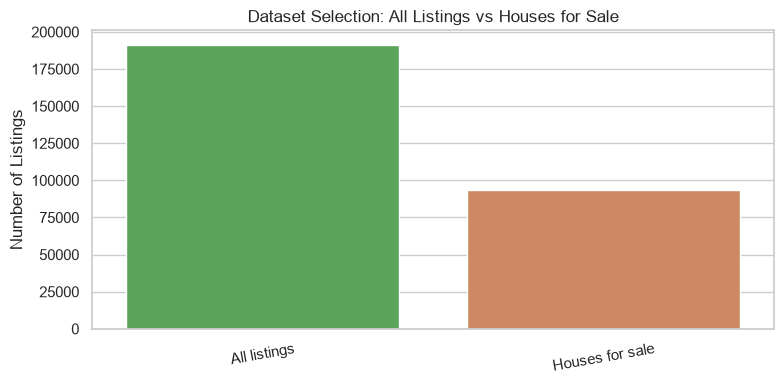

In [43]:
selection_counts = pd.Series({
    "All listings": len(df_clean),
    "Houses for sale": len(df_houses_for_sale)
})

total = len(df_clean)
colors = ["#4FB04C", "#DD8452"]

plt.figure(figsize=(8, 4))
sns.barplot(
    x=selection_counts.index,
    y=selection_counts.values,
    hue=selection_counts.index,
    palette=colors,
    legend=False
)
plt.title("Dataset Selection: All Listings vs Houses for Sale")
plt.ylabel("Number of Listings")
plt.xlabel("")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

**Investigate suspicious prices and area measurements**

The original dataset contains 14 house-for-sale listings priced between PKR 1 and PKR 8, in addition to one house-for-sale listing with a zero price.

In [44]:
lowest_price_mask = df_houses_for_sale['price_review_flag'].eq(True)

df_low_price_review = df_houses_for_sale.loc[lowest_price_mask].copy()

pct_low_price = len(df_low_price_review) / len(df_houses_for_sale) * 100

print("House-for-sale listings priced PKR (1-8):", len(df_low_price_review))
print(f"Percentage of lowest prices: {pct_low_price:.2f}%")

display(df_low_price_review[["property_id", "price", "city", "area", "bedrooms", "baths"]])

House-for-sale listings priced PKR (1-8): 14
Percentage of lowest prices: 0.01%


,property_id,price,city,area,bedrooms,baths
10013,11077891,1,Lahore,5 Marla,3,4.0
10014,11078343,4,Lahore,1 Kanal,5,6.0
25543,13357143,5,Karachi,12 Marla,4,4.0
27718,13656316,6,Karachi,6 Marla,4,4.0
28527,13686015,8,Karachi,1 Kanal,5,5.0
36961,14431910,4,Karachi,15 Marla,7,8.0
78718,16339390,1,Karachi,1 Kanal,5,6.0
108958,16919078,3,Rawalpindi,12 Marla,5,5.0
165134,17295163,1,Karachi,4.8 Marla,4,4.0
165404,17295759,1,Rawalpindi,10 Marla,0,0.0


These prices are not credible as ordinary house listing prices in this dataset. We will exclude these 14 records from the modeling dataset (0.01% of the data is ver low so we can exclude it), while preserving them in df_houses_for_sale for traceability.

In [45]:
df_houses_for_sale = df_houses_for_sale.loc[
    ~lowest_price_mask
].copy()

print("Rows remaining after low-price exclusion:", len(df_houses_for_sale))

Rows remaining after low-price exclusion: 93794


Expected: 93,794 listings after excluding the one zero-price listing already removed during Step 2 and these 14 suspiciously low positive prices.


**Inspect area quality within the selected dataset**

In [46]:
print("Total area quality issues: ", df_houses_for_sale[['area_format_flag', 'are_zero_flag']].any(axis=1).sum())
display(

    df_houses_for_sale.loc[
        df_houses_for_sale['area_format_flag'] |
        df_houses_for_sale['are_zero_flag'],
        [
            "property_id", "price", "city", "area",
            "area_sqft", "area_format_flag", "are_zero_flag"
        ]
    ]
)


Total area quality issues:  14


,property_id,price,city,area,area_sqft,area_format_flag,are_zero_flag
30586,13935017,4400000,Karachi,0 Marla,0.0,False,True
39658,14619957,12500000,Lahore,0 Marla,0.0,False,True
103756,16873061,42500000,Lahore,"4,450 Kanal",20025000.0,True,False
122309,17028927,18000000,Lahore,0 Marla,0.0,False,True
133378,17086430,35000000,Lahore,"4,500 Kanal",20250000.0,True,False
135871,17095118,16500000,Islamabad,0 Marla,0.0,False,True
138049,17108764,2200000,Lahore,0 Marla,0.0,False,True
138517,17108060,31500000,Islamabad,0 Marla,0.0,False,True
154284,17232174,22000000,Rawalpindi,"2,250 Kanal",10125000.0,True,False
169686,17312326,4500000,Lahore,0 Marla,0.0,False,True


In the house-for-sale subset, the earlier inspection identified four comma-formatted area values and ten zero-area records.

Decision: preserve the original area labels, but mark their derived square-foot measurements as missing for modeling. This prevents unverified measurements from being treated as trustworthy numerical inputs.

because Pandas skips NaN in mean(), median(), describe(), so our statistics stay honest.It’s an explicit “unknown” that you can handle deliberately later.

In [47]:
area_quality_mask = df_houses_for_sale['are_zero_flag']

df_houses_for_sale.loc[area_quality_mask, 'area_sqft'] = np.nan

print("Zero-area measurements marked missing:", int(area_quality_mask.sum()))
print("Missing Area_sqft values:", df_houses_for_sale["area_sqft"].isna().sum())
print("Comma-formatted area records retained for review:",
      int(df_houses_for_sale["area_format_flag"].sum()))

display(df_houses_for_sale.loc[df_houses_for_sale['are_zero_flag'].eq(True)])

Zero-area measurements marked missing: 10
Missing Area_sqft values: 10
Comma-formatted area records retained for review: 4


,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,...,area,purpose,bedrooms,date_added,agency,agent,area_sqft,area_format_flag,are_zero_flag,price_review_flag
30586,13935017,476,https://www.zameen.com/Property/karachi_malir_...,House,4400000,Malir,Karachi,Sindh,24.893209,67.195473,...,0 Marla,For Sale,2,2019-05-05,Infinity Properties,Shehzad,NaN,False,True,False
39658,14619957,3965,https://www.zameen.com/Property/johar_town_pha...,House,12500000,Johar Town,Lahore,Punjab,31.474097,74.263802,...,0 Marla,For Sale,5,2019-06-11,Siddique Associates & Builders,Hamza Malik,NaN,False,True,False
122309,17028927,93,https://www.zameen.com/Property/lahore_johar_t...,House,18000000,Johar Town,Lahore,Punjab,31.462347,74.293642,...,0 Marla,For Sale,3,2019-07-01,Saqib Estate & Builders,Malik Saqib Rafiq,NaN,False,True,False
135871,17095118,173,https://www.zameen.com/Property/islamabad_i_10...,House,16500000,I-10,Islamabad,Islamabad Capital,33.648922,73.038969,...,0 Marla,For Sale,5,2019-07-03,Seven Star Enterprises,Ch Ahsan,NaN,False,True,False
138049,17108764,11657,https://www.zameen.com/Property/lahore_katar_b...,House,2200000,Katar Bund Road,Lahore,Punjab,31.474503,74.231476,...,0 Marla,For Sale,2,2019-07-04,Al Karam Estate Advisor,Ishfaq Jutt,NaN,False,True,False
138517,17108060,1705,https://www.zameen.com/Property/bahria_town_ba...,House,31500000,Bahria Town,Islamabad,Islamabad Capital,33.692638,73.218813,...,0 Marla,For Sale,0,2019-07-04,KDF Enterprises,Sardar Danish Amin,NaN,False,True,False
169686,17312326,738,https://www.zameen.com/Property/lahore_alfalah...,House,4500000,Alfalah Town,Lahore,Punjab,31.482881,74.418933,...,0 Marla,For Sale,2,2019-07-16,Pakistan Real Estate,Pakistan Real Estate,NaN,False,True,False
176118,17340289,1784,https://www.zameen.com/Property/bahria_town_ba...,House,19500000,Bahria Town,Lahore,Punjab,31.374195,74.191482,...,0 Marla,For Sale,5,2019-07-17,Al Ghazi Estate & Builders,Hasnain Raza Zaidi,NaN,False,True,False
177572,17342798,718,https://www.zameen.com/Property/rawalpindi_ten...,House,5000000,Tench Bhata,Rawalpindi,Punjab,33.584665,73.035436,...,0 Marla,For Sale,5,2019-07-17,Gillani Real Estate & Construction,Syed Ahmed Gillani,NaN,False,True,False
189485,17450087,3078,https://www.zameen.com/Property/bahria_town_ra...,House,6500000,Bahria Town Rawalpindi,Rawalpindi,Punjab,33.573152,73.110881,...,0 Marla,For Sale,2,2019-07-23,Probiz Enterprises,MushtaqurRehman EhteshamurRehman,NaN,False,True,False


We will handle these missing numerical values during Step 7, using a preprocessing method fitted on training data only.

**Decide which columns belong in the model**

Not every column in a dataset should be a model input.

| Column | Decision | Reason |
|---|---|---|
| `price` | Target (`y`) | Value we want to predict |
| `Area_sqft` | Candidate feature | Represents property size numerically |
| `bedrooms` | Candidate feature | Describes house capacity |
| `baths` | Candidate feature | Describes house facilities |
| `city` | Candidate feature | Captures broad geographic differences |
| `province_name` | Candidate feature | Captures regional differences at the province level |
| `latitude`, `longitude` | Candidate features | Capture geographic location |
| `date_added` | Keep for feature engineering | May provide listing-time context |
| `location` | Reserve for later evaluation | High-cardinality text; may add useful local detail |
| `property_id` | Exclude | Identifier, not a property characteristic |
| `location_id` | Exclude initially | Identifier-like field; geography is represented separately |
| `page_url` | Exclude | Listing URL is not an appropriate baseline predictor |
| `agency`, `agent` | Exclude initially | High-cardinality fields with substantial missingness |
| `property_type`, `purpose` | Exclude from features | Both are constant after our selection |

We will retain the complete selected dataframe for analysis, and create a separate dataframe for the initial modeling inputs.


**Create the modeling dataset and verify it**

In [48]:
feature_cols = [
    "area_sqft",
    "bedrooms",
    "baths",
    "city",
    "province_name",
    "latitude",
    "longitude",
    "date_added"
]

df_modeling = df_houses_for_sale[feature_cols + [target]].copy()

X = df_modeling[feature_cols].copy()
y = df_modeling[target].copy()

print("Selected dataset shape:", df_houses_for_sale.shape)
print("Modeling dataset shape:", df_modeling.shape)
print("Feature matrix X shape:", X.shape)
print("Target y shape:", y.shape)

display(df_modeling.head())

Selected dataset shape: (93794, 21)
Modeling dataset shape: (93794, 9)
Feature matrix X shape: (93794, 8)
Target y shape: (93794,)


,area_sqft,bedrooms,baths,city,province_name,latitude,longitude,date_added,price
0,27000.0,0,0.0,Lahore,Punjab,31.483869,74.325686,2019-07-17,220000000
1,4500.0,5,5.0,Lahore,Punjab,31.431593,74.179980,2018-10-06,40000000
2,2025.0,3,0.0,Lahore,Punjab,31.499348,74.416959,2019-07-03,9500000
3,4500.0,8,7.0,Lahore,Punjab,31.522069,74.355512,2019-04-04,125000000
4,2475.0,6,5.0,Lahore,Punjab,31.506483,74.286017,2019-04-04,21000000


**Verify the selected features**

The cross-tabulation verifies how cities map to provinces. In this dataset, Karachi belongs to Sindh, Lahore, Rawalpindi, and Faisalabad belong to Punjab, and Islamabad belongs to Islamabad Capital.

In [49]:
print("Missing values in selected features:")
display(
    df_modeling[feature_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)

print("\nProvince distribution:")
display(
    df_modeling["province_name"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nCity and province combinations:")
display(
    pd.crosstab(
        df_modeling["city"],
        df_modeling["province_name"],
        margins=True
    )
)

Missing values in selected features:


,Missing_Count
area_sqft,10
baths,1
bedrooms,0
city,0
province_name,0
latitude,0
longitude,0
date_added,0



Province distribution:


,Count
province_name,
Punjab,59458
Sindh,21594
Islamabad Capital,12742



City and province combinations:


province_name,Islamabad Capital,Punjab,Sindh,All
city,,,,
Faisalabad,0,5160,0,5160
Islamabad,12742,0,0,12742
Karachi,0,0,21594,21594
Lahore,0,42974,0,42974
Rawalpindi,0,11324,0,11324
All,12742,59458,21594,93794


Verify the target distribution:

In [50]:
print("Target summary (PKR):")
display(
    y.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame("Price")
)

Target summary (PKR):


,Price
count,9.379400e+04
mean,2.915566e+07
std,4.365843e+07
min,1.600000e+04
1%,2.500000e+06
5%,4.000000e+06
25%,9.500000e+06
50%,1.600000e+07
75%,3.250000e+07
95%,9.500000e+07


**Final selection audit**



In [51]:
print("Final modeling rows:", len(df_modeling))
print("Duplicate rows:", df_modeling.duplicated().sum())
print("Missing target values:", df_modeling[target].isna().sum())
print("Non-positive target values:", (df_modeling[target] <= 0).sum())

print("\nMissing values by model column:")
display(
    df_modeling.isna().sum().to_frame("Missing Count")
    .sort_values("Missing Count", ascending=False)
)

Final modeling rows: 93794
Duplicate rows: 10652
Missing target values: 0
Non-positive target values: 0

Missing values by model column:


,Missing Count
area_sqft,10
baths,1
bedrooms,0
city,0
province_name,0
latitude,0
longitude,0
date_added,0
price,0


# Step 4 — Exploratory Data Analysis (EDA)

*Understand which factors influence house sale prices in your Pakistan real-estate dataset before building a machine-learning model.*

We will use df_houses_for_sale from Step 3, not the entire original dataset. This keeps the analysis focused on houses listed for sale, rather than mixing houses with flats, rental listings, and other property types.
We will also preserve legitimate expensive properties. An unusually high price is a reason to investigate a listing, not automatically a reason to delete or cap it.

**Establish the EDA dataset**

Used the cleaned house-for-sale subset produced in Step 3.

In [52]:
eda_df = df_houses_for_sale.copy()

sns.set_theme(style="whitegrid", context="notebook")

print("EDA dataset shape:", eda_df.shape)
print("\nTarget summary:")
display(
    eda_df["price"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
    .round(2)
)


EDA dataset shape: (93794, 21)

Target summary:


,price
count,9.379400e+04
mean,2.915566e+07
std,4.365843e+07
min,1.600000e+04
25%,9.500000e+06
50%,1.600000e+07
75%,3.250000e+07
90%,6.000000e+07
95%,9.500000e+07
99%,2.000000e+08


**Analyze the target variable (price)**

Is the target normally distributed, skewed, or dominated by extreme prices?

A histogram shows the distribution; a log-scale histogram helps reveal the shape among lower and middle prices; a box plot highlights extreme values.

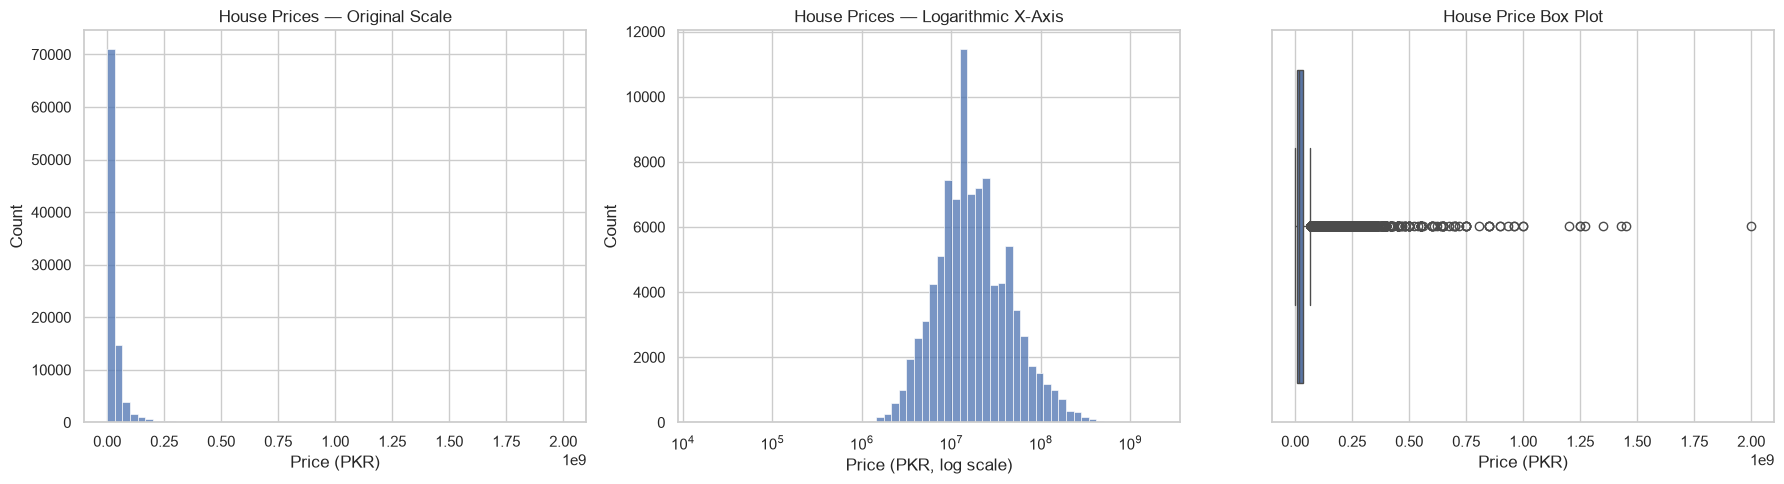

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=eda_df, x="price", bins=60, ax=axes[0])
axes[0].set_title("House Prices — Original Scale")
axes[0].set_xlabel("Price (PKR)")

sns.histplot(
    data=eda_df.loc[eda_df["price"] > 0],
    x="price",
    bins=60,
    log_scale=True,
    ax=axes[1]
)
axes[1].set_title("House Prices — Logarithmic X-Axis")
axes[1].set_xlabel("Price (PKR, log scale)")

sns.boxplot(data=eda_df, x="price", ax=axes[2])
axes[2].set_title("House Price Box Plot")
axes[2].set_xlabel("Price (PKR)")

plt.tight_layout()
plt.show()

Calculating the statistics that help explain the plots:

In [54]:
price_stats = eda_df["price"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(price_stats.to_frame("Price (PKR)").round(0))

q1 = eda_df["price"].quantile(0.25)
q3 = eda_df["price"].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

print(f"IQR: PKR {iqr:,.0f}")
print(f"Upper IQR fence: PKR {upper_fence:,.0f}")
print("Prices above upper fence:", int((eda_df["price"] > upper_fence).sum()))

,Price (PKR)
count,9.379400e+04
mean,2.915566e+07
std,4.365843e+07
min,1.600000e+04
25%,9.500000e+06
50%,1.600000e+07
75%,3.250000e+07
90%,6.000000e+07
95%,9.500000e+07
99%,2.000000e+08


IQR: PKR 23,000,000
Upper IQR fence: PKR 67,000,000
Prices above upper fence: 7952


**Findings:**

- The distribution is strongly right-skewed: most houses are far below the maximum price.
- The mean is about PKR 29.16 million, while the median is PKR 16 million. A relatively small number of expensive listings pull the mean upward.
- The maximum of PKR 2 billion is much higher than the 99th percentile of PKR 200 million, so it deserves investigation—but it is not automatically an error.
- The box plot will flag many expensive houses because the dataset covers a wide range of property sizes and markets. Those points are candidates for investigation, not automatic deletion.

Decision: Keep price in its original PKR units for now. We can later compare models trained on raw prices with models using a log-transformed target, fitting any transformations correctly within the training workflow.

**Compare house prices by city and province**

Does location help explain why one house costs more than another?

The median is a useful starting point because extreme prices can distort the mean.

In [55]:
city_wise_prices = (
    eda_df.groupby("city")['price']
    .agg(
        Listings="count",
        Median_Price="median",
        Mean_Price="mean"
    )
    .sort_values("Median_Price", ascending=False)
)

province_wise_prices = (
    eda_df.groupby("province_name")['price']
    .agg(
        Listings="count",
        Median_Price="median",
        Mean_Price="mean"
    )
    .sort_values("Median_Price", ascending=False)
)

display(city_wise_prices)
display(province_wise_prices)

,Listings,Median_Price,Mean_Price
city,,,
Islamabad,12742,21000000.0,3.747831e+07
Karachi,21594,19000000.0,4.146568e+07
Lahore,42974,16500000.0,2.581832e+07
Rawalpindi,11324,12000000.0,1.582244e+07
Faisalabad,5160,9500000.0,1.414286e+07


,Listings,Median_Price,Mean_Price
province_name,,,
Islamabad Capital,12742,21000000.0,3.747831e+07
Sindh,21594,19000000.0,4.146568e+07
Punjab,59458,14500000.0,2.290133e+07


Visualize the median prices:

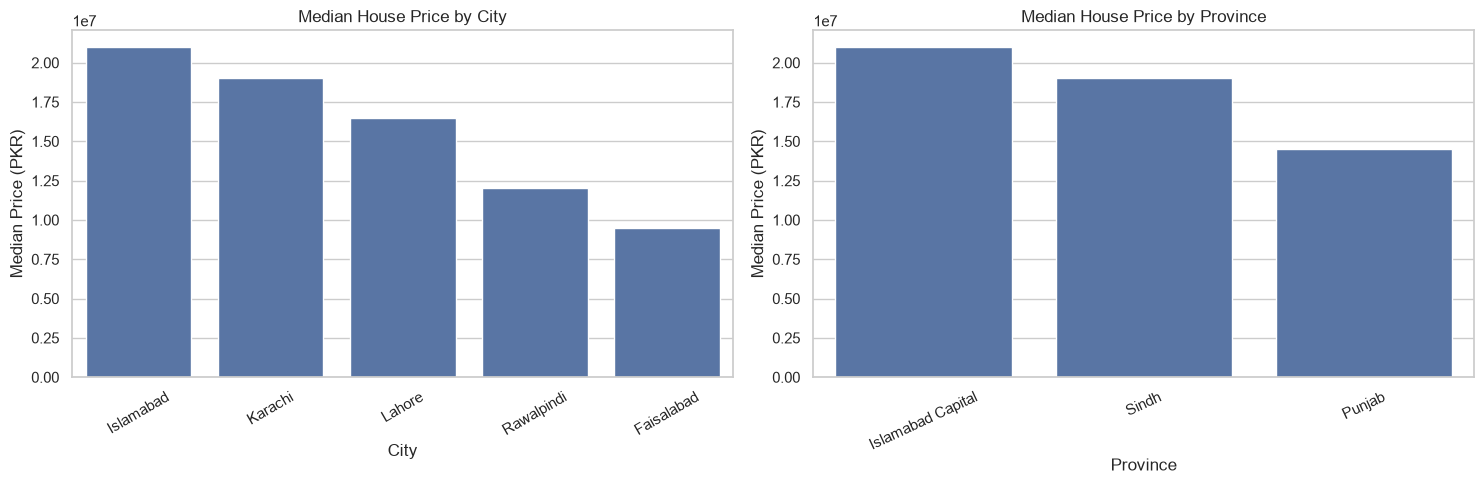

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=city_wise_prices.reset_index(),
    x="city",
    y="Median_Price",
    ax=axes[0]
)
axes[0].set_title("Median House Price by City")
axes[0].set_xlabel("City")
axes[0].set_ylabel("Median Price (PKR)")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=province_wise_prices.reset_index(),
    x="province_name",
    y="Median_Price",
    ax=axes[1]
)
axes[1].set_title("Median House Price by Province")
axes[1].set_xlabel("Province")
axes[1].set_ylabel("Median Price (PKR)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

**Findings:**

The median prices in the filtered dataset are approximately:

| City | Median price |
|---|---|
| Islamabad | PKR 21 million |
| Karachi | PKR 19 million |
| Lahore | PKR 16.5 million |
| Rawalpindi | PKR 12 million |
| Faisalabad | PKR 9.5 million |

These figures describe the listings in this dataset, not every house in each city.

Decision: Retain both city and province_name for now. The province feature overlaps with city because each of the five cities belongs to a single province in this dataset. We can assess whether province adds useful predictive information during model development.

**Investigate area versus price**

Do larger houses generally have higher asking prices? Are any area measurements suspicious?

Use Area_sqft, the numeric area feature created during cleaning. Do not use the original text column area for numerical correlation.

**Calculate the relationship**

Spearman Correlation:

converts values to ranks first, then measures whether one variable consistently rises (or falls) with the other, even if the relationship is curved. It’s robust to outliers and skew.

In [57]:
area_price_data = eda_df[["area_sqft", "price"]].dropna()
area_price_data = area_price_data[
    (area_price_data["area_sqft"] > 0) &
    (area_price_data["price"] > 0)
]

print(
    "Spearman correlation:",
    round(area_price_data["area_sqft"].corr(
        area_price_data["price"], method="spearman"
    ), 3)
)

Spearman correlation: 0.852


In this dataset, the Spearman correlation is approximately 0.85, indicating a strong positive association: larger houses generally have higher asking prices.

Correlation does not mean area alone determines price. Location, construction quality, condition, and other characteristics also matter.

Now Visualize the relationship:

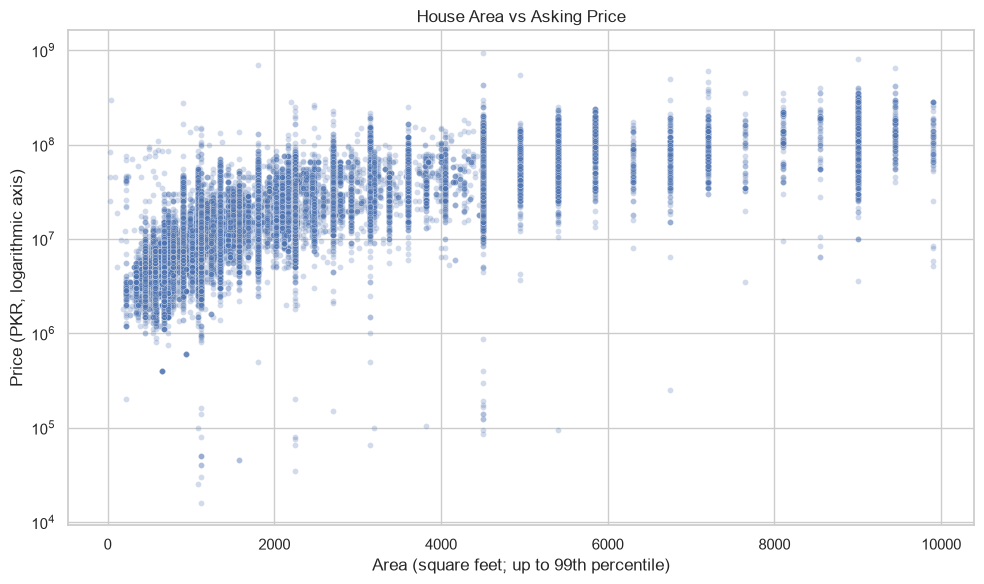

In [58]:
area_plot_df = area_price_data.copy()

# Limit only the plotted observations to the 99th area percentile.
# This does not remove rows from eda_df or the modeling dataset.
area_limit = area_plot_df["area_sqft"].quantile(0.99)
area_plot_df = area_plot_df[
    area_plot_df["area_sqft"] <= area_limit
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=area_plot_df,
    x="area_sqft",
    y="price",
    alpha=0.25,
    s=18
)

plt.yscale("log")
plt.title("House Area vs Asking Price")
plt.xlabel("Area (square feet; up to 99th percentile)")
plt.ylabel("Price (PKR, logarithmic axis)")
plt.tight_layout()
plt.show()

How to read the scatter plot:

- An upward pattern means larger houses tend to cost more.
- A wide vertical spread means houses of similar sizes can have very different prices.
- The logarithmic price axis makes lower and middle prices easier to distinguish.
- The area limit is only for visualization. It does not remove extreme-area listings from the dataset.

**Analyze bedrooms and bathrooms**

Do houses with more bedrooms or bathrooms tend to have higher asking prices?

First, ensure the values are numeric for analysis. This does not overwrite the original columns.

In [59]:
for col in ["bedrooms", "baths"]:
    eda_df[f"{col}_eda"] = pd.to_numeric(
        eda_df[col], errors="coerce"
    )

In [60]:
for col in ["bedrooms_eda", "baths_eda"]:
    summary = (
        eda_df.groupby(col)["price"]
        .agg(
            Listings="count",
            Median_Price="median"
        )
        .sort_index()
    )

    print(f"\nPrice summary by {col}:")
    display(summary.round(0))


Price summary by bedrooms_eda:


,Listings,Median_Price
bedrooms_eda,,
0,10981,12500000.0
1,461,3400000.0
2,6455,5100000.0
3,22009,11000000.0
4,17522,16500000.0
5,21284,27000000.0
6,10056,35000000.0
7,2485,39000000.0
8,1195,37500000.0



Price summary by baths_eda:


,Listings,Median_Price
baths_eda,,
0.0,22484,14500000.0
1.0,924,3700000.0
2.0,5905,5500000.0
3.0,15565,11000000.0
4.0,13317,13500000.0
5.0,13260,22500000.0
6.0,14775,34000000.0
7.0,4853,37500000.0
8.0,1692,44000000.0


Plot the common categories. The minimum listing count avoids letting categories with very few observations dominate the chart.

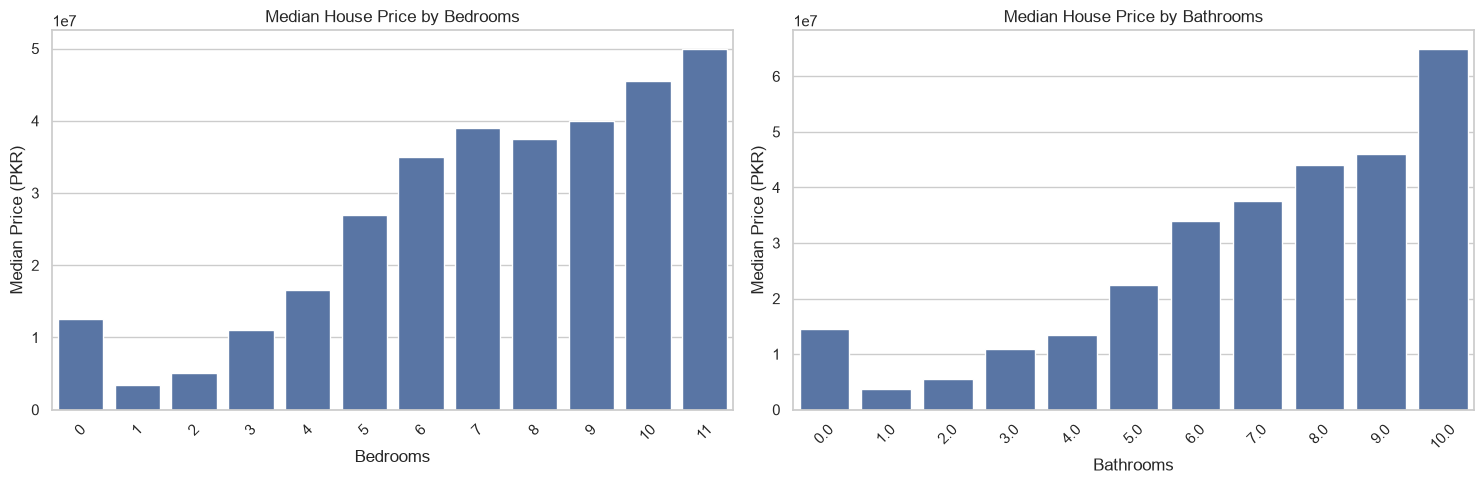

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, col, label in [
    (axes[0], "bedrooms_eda", "Bedrooms"),
    (axes[1], "baths_eda", "Bathrooms")
]:
    summary = (
        eda_df.groupby(col)["price"]
        .agg(Listings="count", Median_Price="median")
        .reset_index()
    )

    summary = summary[summary["Listings"] >= 100]

    sns.barplot(
        data=summary,
        x=col,
        y="Median_Price",
        ax=ax
    )

    ax.set_title(f"Median House Price by {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Median Price (PKR)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Interpretation:**

- Prices generally tend to increase across common bedroom and bathroom counts.
- The pattern may not increase perfectly at every count because houses also differ in location, area, quality, and other features.
- Zero counts may reflect incomplete listing information or unusual properties. Investigate them instead of automatically replacing all zeros with missing values.
- Very high bedroom or bathroom counts should be checked against the corresponding area and listing details before any changes are made.

Decision: Keep bedrooms and baths as candidate predictors. not automatically capping their values.

**Examine listing dates**

Does the number of listings or their median price vary over time?

The recorded dates range from August 2018 to August 2019. This analysis can help us understand the data collection period and whether dates may be useful features.

In [62]:
eda_df["date_added"] = pd.to_datetime(
    eda_df["date_added"], errors="coerce"
)

monthly_summary = (
    eda_df.dropna(subset=["date_added"])
    .assign(
        month=lambda d: d["date_added"].dt.to_period("M").astype(str)
    )
    .groupby("month")
    .agg(
        Listings=("price", "size"),
        Median_Price=("price", "median")
    )
    .reset_index()
)

display(monthly_summary)

,month,Listings,Median_Price
0,2018-08,1082,12500000.0
1,2018-09,1322,12500000.0
2,2018-10,1539,12000000.0
3,2018-11,1323,12000000.0
4,2018-12,1352,12000000.0
5,2019-01,1514,13000000.0
6,2019-02,2449,15000000.0
7,2019-03,2951,16500000.0
8,2019-04,4340,16500000.0
9,2019-05,6474,16650000.0


Visualize listing counts and median prices separately:

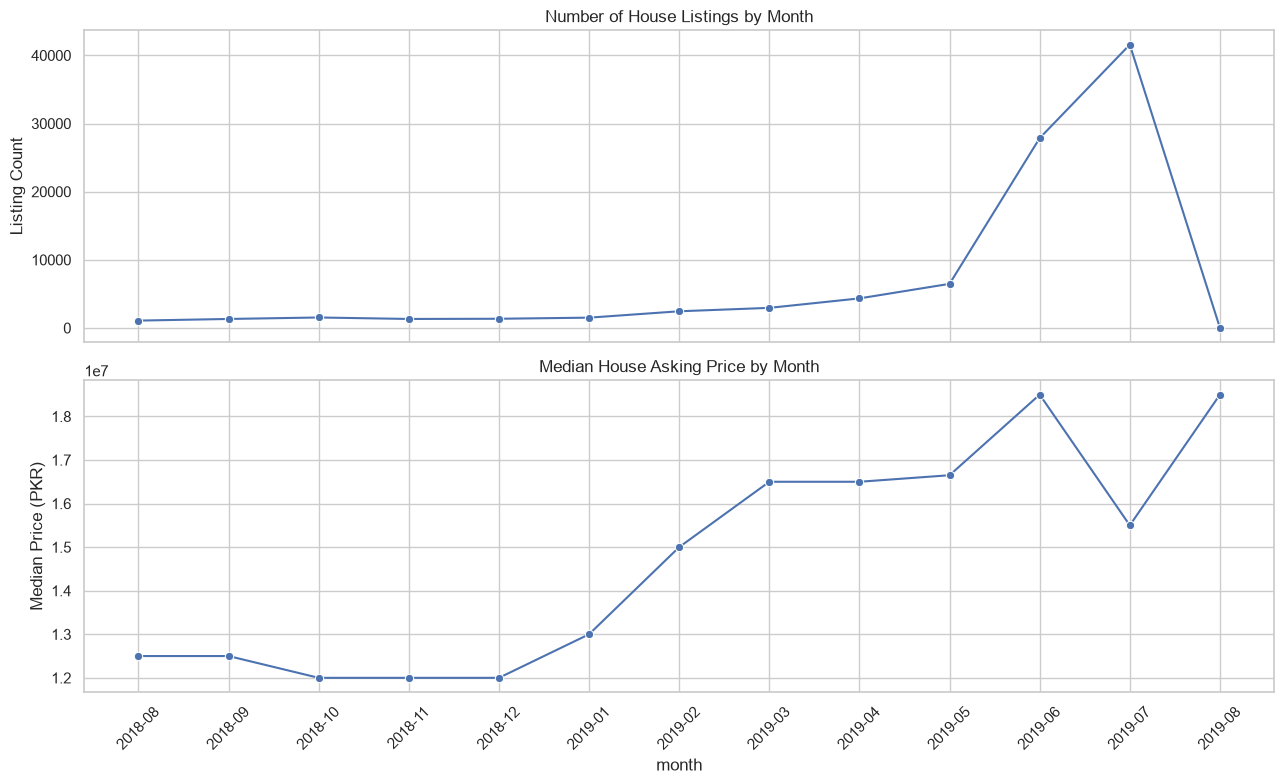

In [63]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

sns.lineplot(
    data=monthly_summary,
    x="month",
    y="Listings",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Number of House Listings by Month")
axes[0].set_ylabel("Listing Count")

sns.lineplot(
    data=monthly_summary,
    x="month",
    y="Median_Price",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Median House Asking Price by Month")
axes[1].set_ylabel("Median Price (PKR)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Interpretations:**

- Changes in listing counts may reflect publishing patterns, source coverage, or the availability of records.
- Changes in monthly median price may result from different types of houses being listed in different months—not necessarily changes in the price of the same properties.
- This dataset is historical. A model trained on 2018–2019 listings should not be assumed to predict current 2026 prices accurately.

Decision: Retain date_added for possible feature engineering. Do not infer a market trend from these plots alone.

**Review numerical relationships**

Which numeric features move together, and which have the strongest overall relationship with price?

Using Spearman correlation because relationships may be monotonic without being linear.

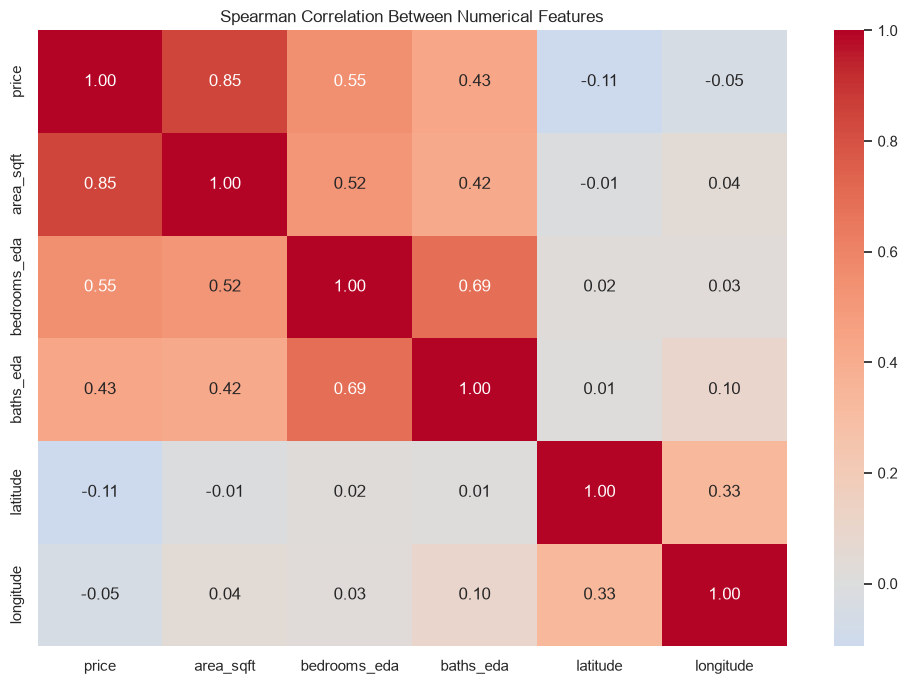

In [64]:
numeric_cols = [
    "price",
    "area_sqft",
    "bedrooms_eda",
    "baths_eda",
    "latitude",
    "longitude"
]

corr_matrix = eda_df[numeric_cols].corr(method='spearman')

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Spearman Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

**Interpretations:**

- Area has a strong positive association with price (approximately 0.85).



- Bedrooms and bathrooms have positive associations with price, generally weaker than area.



- Latitude and longitude may have weak overall correlations even when geography matters. The relationship between coordinates and prices can be nonlinear and vary between cities.



- Correlation does not establish causation and does not, by itself, justify removing a feature.


Decision: Retain area, bedrooms, bathrooms, latitude, and longitude for now. Compare their usefulness during model development rather than eliminating them solely from this heatmap.

**Review missing values in candidate features**

Which candidate features have missing values that we will need to handle before training?



In [65]:
feature_cols = [
    "area_sqft",
    "bedrooms_eda",
    "baths_eda",
    "city",
    "province_name",
    "latitude",
    "longitude",
    "date_added"
]

missing_summary = pd.DataFrame({
    "Missing_Count": eda_df[feature_cols].isna().sum(),
    "Missing_Percentage": eda_df[feature_cols].isna().mean() * 100
}).sort_values("Missing_Percentage", ascending=False)

display(missing_summary.round(2))

,Missing_Count,Missing_Percentage
area_sqft,10,0.01
baths_eda,1,0.00
bedrooms_eda,0,0.00
city,0,0.00
province_name,0,0.00
latitude,0,0.00
longitude,0,0.00
date_added,0,0.00



**Findings:**

This summary is based on the candidate features only. The original agency and agent columns also contain substantial missingness, but they are excluded from the initial modeling feature set.

Decision: Do not impute values at this stage. In Step 7, fit imputers and other data-dependent preprocessing using the training data only, then apply the fitted transformations to the test data. This prevents data leakage.

**EDA findings and decisions**

| Finding | Decision |
|---|---|
| House prices are strongly right-skewed | Compare raw and log-transformed targets later |
| Some prices are extremely high | Investigate; do not automatically delete or cap |
| Median prices differ by city | Retain city |
| Province overlaps with city | Keep both initially; assess redundancy later |
| Area has a strong positive association with price | Retain `area_sqft`; investigate extreme measurements |
| Bedrooms and bathrooms relate to price | Retain both; inspect unusual counts |
| Listing dates cover a historical period | Retain for possible feature engineering; recognize the age of the data |
| Numerical correlations do not capture every relationship | Keep plausible features for model comparison |
| Some candidate features may contain missing values | Handle them in Step 7 after splitting |

# Step 5 — Train-Test Split

*Separate the dataset into two parts so we can train the house-price model on one part and evaluate it on data the model has never seen.*

- Training set: Used to learn patterns between property features and sale prices.
- Test set: Reserved for the final evaluation of how well the trained model predicts unseen listings.

We will use an 80/20 split: 80% for training and 20% for testing. For a dataset of approximately 93,794 listings, that is roughly 75,035 training rows and 18,759 test rows.

Critical rule: Split before fitting imputers, encoders, scalers, feature-selection procedures, or other preprocessing steps that learn from the data. Otherwise, information from the test set can leak into training.

**Prepare the final modeling table**

We will rebuild df_modeling from df_houses_for_sale so it includes the final cleaning decisions from Step 3. This also avoids accidentally using stale data from an earlier copy.

Use bedrooms and baths as numeric columns in the modeling table. Any values that cannot be converted become missing and will be handled in Step 7—not imputed now.

In [66]:
from sklearn.model_selection import train_test_split

feature_cols = [
    "area_sqft",
    "bedrooms",
    "baths",
    "city",
    "province_name",
    "latitude",
    "longitude",
    "date_added"
]

# Rebuild the modeling table from the latest cleaned subset
df_modeling = df_houses_for_sale[feature_cols + [target]].copy()

# Convert numerical columns without imputing missing values
for col in ["area_sqft", "bedrooms", "baths", "latitude", "longitude", "price"]:
    df_modeling[col] = pd.to_numeric(
        df_modeling[col], errors="coerce"
    )

# Parse dates without filling missing dates
df_modeling["date_added"] = pd.to_datetime(
    df_modeling["date_added"], errors="coerce"
)

print("Modeling table shape:", df_modeling.shape)
print("Missing target values:", df_modeling["price"].isna().sum())
print("Zero target values:", df_modeling["price"].eq(0).sum())
print("Nonpositive target values:", (df_modeling["price"] <= 0).sum())



Modeling table shape: (93794, 9)
Missing target values: 0
Zero target values: 0
Nonpositive target values: 0


In [67]:
X = df_modeling[feature_cols].copy()
y = df_modeling[target].copy()

print("Rows available for splitting:", len(df_modeling))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Missing feature values:", int(X.isna().sum().sum()))

Rows available for splitting: 93794
Feature matrix shape: (93794, 8)
Target shape: (93794,)
Missing feature values: 11


we have not dropped rows with missing features. Those can be handled within a training pipeline.

**Split into training and test sets**

In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (75035, 8)
X_test:  (18759, 8)
y_train: (75035,)
y_test:  (18759,)


We are using a random split because the initial goal is to estimate performance on unseen listings drawn from a similar population. If the goal changes to predicting prices for a future time period, a chronological split would be more appropriate.

**Verify the split**

In [69]:
split_summary = pd.DataFrame({
    "Dataset": ["Full", "Training", "Test"],
    "Rows": [len(df_modeling), len(X_train), len(X_test)],
    "Percentage": [
        100,
        len(X_train) / len(df_modeling) * 100,
        len(X_test) / len(df_modeling) * 100
    ],
    "Median_Price": [
        y.median(),
        y_train.median(),
        y_test.median()
    ],
    "Mean_Price": [
        y.mean(),
        y_train.mean(),
        y_test.mean()
    ]
})

display(split_summary.round(2))

,Dataset,Rows,Percentage,Median_Price,Mean_Price
0,Full,93794,100.0,16000000.0,29155655.35
1,Training,75035,80.0,16000000.0,29138015.67
2,Test,18759,20.0,16000000.0,29226213.12


The training and test price distributions will not match perfectly, but their medians and means should be reasonably comparable. A large difference may occur by chance, particularly with a strongly skewed target, and should prompt further inspection.

Check that the indexes do not overlap:


In [70]:
print("Overlapping training/test indexes:",
      len(set(X_train.index).intersection(set(X_test.index))))

print("Training target missing values:", y_train.isna().sum())
print("Test target missing values:", y_test.isna().sum())

Overlapping training/test indexes: 0
Training target missing values: 0
Test target missing values: 0


**Interpretations**

- Use X_train and y_train to explore modeling choices, fit preprocessing, and train models.
- Use X_test and y_test for final evaluation after selecting the model.
- Fit imputers, encoders, scalers, and data-driven transformations using the training data only.
- Do not use test-set results to repeatedly tune the model; use cross-validation within the training data for model selection.

important detail: date_added is still a datetime column. We will extract useful date features in Step 6 — Feature Engineering, then encode categorical columns and handle missing values in Step 7.

# Step 6 — Feature Engineering

*Transform existing columns into more useful features for predicting house sale prices, without introducing information leakage from the test set.*

We will build on the X_train, X_test, y_train, and y_test created in Step 5. We will not return to the full dataset to create a new split.

Our initial feature set includes:

- Area_sqft
- bedrooms
- baths
- city
- province_name
- latitude
- longitude
- date_added

The main opportunity for feature engineering is date_added, because machine-learning models generally cannot use a raw datetime column directly. We will also investigate whether area, bedroom count, and bathroom count can produce useful derived features.

**Extract features from date_added**

A raw date can contain useful information, such as the month or year when a property was listed. We will extract calendar features and then remove the raw datetime column from the model inputs.
For this dataset, listing dates span approximately August 2018 to August 2019. Because the period is short, we should not assume that a complicated time feature will improve predictions.

In [71]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

def add_date_features(data):
    data = data.copy()

    dates = pd.to_datetime(data['date_added'], errors='coerce')

    data['listing_year'] = dates.dt.year
    data["listing_month"] = dates.dt.month
    data["listing_dayofweek"] = dates.dt.dayofweek

    # Cyclic encoding preserves the fact that December and January
    # are neighboring months.
    data["listing_month_sin"] = np.sin(
        2 * np.pi * data["listing_month"] / 12
    )
    data["listing_month_cos"] = np.cos(
        2 * np.pi * data["listing_month"] / 12
    )

    # The extracted features replace the raw datetime column
    data = data.drop(columns=["date_added"])

    return data

X_train_fe = add_date_features(X_train_fe)
X_test_fe = add_date_features(X_test_fe)

print("Training features:", X_train_fe.shape)
print("Test features:", X_test_fe.shape)

display(X_train_fe.head())

Training features: (75035, 12)
Test features: (18759, 12)


,area_sqft,bedrooms,baths,city,province_name,latitude,longitude,listing_year,listing_month,listing_dayofweek,listing_month_sin,listing_month_cos
10052,4500.0,5,7.0,Lahore,Punjab,31.500556,74.367728,2019,7,2,-5.000000e-01,-0.866025
93644,2700.0,5,5.0,Lahore,Punjab,31.469082,74.256549,2019,6,2,1.224647e-16,-1.000000
92265,2250.0,5,5.0,Rawalpindi,Punjab,33.550408,73.115473,2019,6,3,1.224647e-16,-1.000000
37237,2250.0,4,4.0,Rawalpindi,Punjab,33.543004,73.067576,2019,6,3,1.224647e-16,-1.000000
211,9900.0,8,8.0,Lahore,Punjab,31.486906,74.385896,2019,6,1,1.224647e-16,-1.000000


Feature	What it represents

| Column | Description |
|---|---|
| `listing_year` | Year the property was listed |
| `listing_month` | Month the property was listed |
| `listing_dayofweek` | Day of the week the listing date falls on, where Monday = 0 |
| `listing_month_sin` | Cyclic representation of the month |
| `listing_month_cos` | Complementary cyclic representation of the month |

The sine and cosine features encode the month as a cycle, rather than treating December and January as far apart. However, because the data covers only about one year, these features may reflect listing-source patterns rather than genuine market seasonality. We will assess their usefulness later.

**Create area-per-room features**

A house's area relative to its bedroom count or bathroom count may help describe its layout. These are candidate features, not guaranteed improvements.

We must avoid division by zero. When the bedroom or bathroom count is zero or missing, the ratio should be missing and handled in Step 7.

In [72]:
def add_room_ratio_features(data):
    data = data.copy()

    bedrooms = pd.to_numeric(data["bedrooms"], errors="coerce")
    baths = pd.to_numeric(data["baths"], errors="coerce")
    area = pd.to_numeric(data["area_sqft"], errors="coerce")

    data["area_per_bedroom"] = (
        area / bedrooms.where(bedrooms > 0)
    )

    data["area_per_bathroom"] = (
        area / baths.where(baths > 0)
    )

    return data

X_train_fe = add_room_ratio_features(X_train_fe)
X_test_fe = add_room_ratio_features(X_test_fe)

display(
    X_train_fe[
        [
            "area_sqft",
            "bedrooms",
            "baths",
            "area_per_bedroom",
            "area_per_bathroom"
        ]
    ].head(10)
)

,area_sqft,bedrooms,baths,area_per_bedroom,area_per_bathroom
10052,4500.0,5,7.0,900.0,642.857143
93644,2700.0,5,5.0,540.0,540.000000
92265,2250.0,5,5.0,450.0,450.000000
37237,2250.0,4,4.0,562.5,562.500000
211,9900.0,8,8.0,1237.5,1237.500000
10076,3150.0,5,5.0,630.0,630.000000
166078,3150.0,6,7.0,525.0,450.000000
70491,450.0,2,3.0,225.0,150.000000
64169,1800.0,3,5.0,600.0,360.000000
43116,5850.0,6,6.0,975.0,975.000000


**Interpretation:**

- Area_per_bedroom measures square feet per bedroom.
- Area_per_bathroom measures square feet per bathroom.
- A large ratio may reflect a spacious house, a low room count, or an unusual listing.
- These ratios can be unstable when the denominator is small, so we must inspect their distributions and missingness.

**Inspect the new features**

In [73]:
ratio_cols = ["area_per_bedroom", "area_per_bathroom"]

display(
    X_train_fe[ratio_cols].describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .round(2)
)

display(
     X_train_fe[ratio_cols]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .to_frame("Missing_Percentage")
)

,area_per_bedroom,area_per_bathroom
count,66281.00,57087.00
mean,868.28,781.67
std,40029.92,35719.73
min,4.50,3.21
25%,309.38,281.25
50%,450.00,450.00
75%,675.00,642.86
95%,1125.00,1125.00
99%,1875.00,1800.00
max,6750000.00,6750000.00


,Missing_Percentage
area_per_bedroom,11.67
area_per_bathroom,23.92


Visualize the distributions:

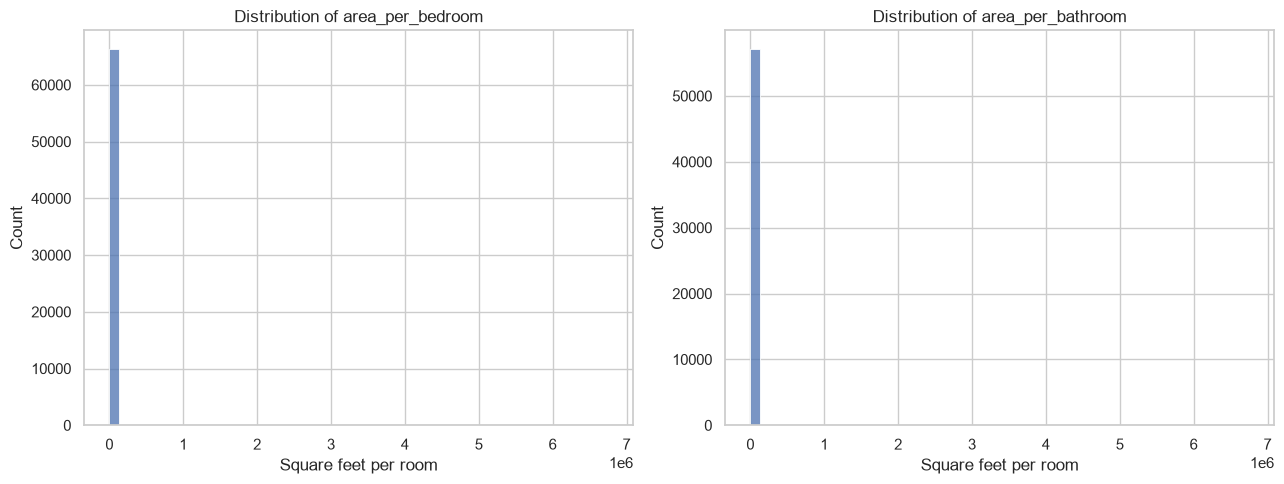

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col in zip(axes, ratio_cols):
    sns.histplot(
        data=X_train_fe,
        x=col,
        bins=50,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Square feet per room")

plt.tight_layout()
plt.show()

Severe right skew with extreme outliers. The bulk of the properties (roughly 66,000 in the bedroom plot and 57,000 in the bathroom plot) have normal values, but a few rows have enormous ones.


**Validate the engineered features**

Before moving on, check that training and test sets have the same feature columns in the same order.

In [75]:

print("Same feature columns:",
      X_train_fe.columns.equals(X_test_fe.columns))

print("Total modeling rows: ", len(X_train_fe) + len(X_test_fe))
print("\nTraining shape:", X_train_fe.shape)
print("Test shape:", X_test_fe.shape)

print("\nRemaining datetime columns:")
print(
    X_train_fe.select_dtypes(
        include=["datetime", "datetimetz"]
    ).columns.tolist()
)

print("\nTraining feature types:")
display(X_train_fe.dtypes.to_frame("Data_Type"))

Same feature columns: True
Total modeling rows:  93794

Training shape: (75035, 14)
Test shape: (18759, 14)

Remaining datetime columns:
[]

Training feature types:


,Data_Type
area_sqft,float64
bedrooms,int64
baths,float64
city,str
province_name,str
latitude,float64
longitude,float64
listing_year,int32
listing_month,int32
listing_dayofweek,int32


At this point, the features are:

- Original features: area, bedrooms, bathrooms, city, province, latitude, and longitude.
- Date-derived features: year, month, day of week, month sine, and month cosine.
- Ratio features: area per bedroom and area per bathroom.

We should not assume that adding more features always improves a model. In Step 8, we can compare a baseline model against a model using these engineered features.

# Step 7 — Data Preprocessing

*Prepare the engineered training and test features so they can be used by machine-learning algorithms.*

In Step 6, we created X_train_fe and X_test_fe. We will use those datasets rather than returning to the original data.
Our preprocessing plan is:

1. Separate numerical and categorical features.
2. Check missing values and invalid feature values.
3. Impute missing numerical and categorical values.
4. One-hot encode categorical features.
5. Scale numerical features for models that benefit from scaling.
6. Combine the transformations into a single scikit-learn pipeline.
7. Verify that the training and test data have compatible transformations.

Leakage prevention: Every preprocessing step that learns values from data will be fitted on X_train_fe only. The test set will receive the already-fitted transformations, without influencing them.


**Checking for missing values in train & test data**

In [76]:
missing_values = pd.DataFrame({
    "Train Missing": X_train_fe.isnull().sum(),
    "Train Missing (%)": X_train_fe.isnull().mean() * 100,
    "Test_Missing": X_test_fe.isna().sum(),
    "Test_Missing_%": X_test_fe.isna().mean() * 100
})

display(missing_values.round(2))

,Train Missing,Train Missing (%),Test_Missing,Test_Missing_%
area_sqft,7,0.01,3,0.02
bedrooms,0,0.00,0,0.00
baths,1,0.00,0,0.00
city,0,0.00,0,0.00
province_name,0,0.00,0,0.00
latitude,0,0.00,0,0.00
longitude,0,0.00,0,0.00
listing_year,0,0.00,0,0.00
listing_month,0,0.00,0,0.00
listing_dayofweek,0,0.00,0,0.00


These are the verified results after applying our previously agreed cleaning decisions:

| Feature | Training missing | Test missing | Interpretation |
|---|---|---|---|
| `Area_sqft` | 7 (0.009%) | 3 (0.016%) | A small number of area measurements are unavailable |
| `baths` | 1 (0.001%) | 0 | The implausible 403-bath value was flagged during cleaning |
| `Area_per_bedroom` | 8,754 (11.667%) | 2,236 (11.920%) | The ratio is undefined when area is missing or bedrooms are zero |
| `Area_per_bathroom` | 17,948 (23.920%) | 4,546 (24.234%) | The ratio is undefined when area is missing or bathrooms are zero |

The other selected features have no missing values in this split.

What this means: The high missing percentages in the two ratio features are not necessarily evidence of poor data quality. These ratios are mathematically undefined for listings with zero bedrooms or bathrooms. We should preserve that distinction instead of deleting those listings.

**Identify numerical and categorical features**

Our 14 features from Step 6 fall into these groups:

- Numerical: area, bedrooms, bathrooms, coordinates, date-derived features, and room ratios.
- Categorical: city and province.


In [77]:
# Work on copies
X_train_prep = X_train_fe.copy()
X_test_prep = X_test_fe.copy()

numeric_cols = [
    "area_sqft",
    "bedrooms",
    "baths",
    "latitude",
    "longitude",
    "listing_year",
    "listing_month",
    "listing_dayofweek",
    "listing_month_sin",
    "listing_month_cos",
    "area_per_bedroom",
    "area_per_bathroom"
]

categorical_cols = [
    "city",
    "province_name"
]

# Convert numeric columns consistently in train and test
for col in numeric_cols:
    X_train_prep[col] = pd.to_numeric(
        X_train_prep[col], errors="coerce"
    )
    X_test_prep[col] = pd.to_numeric(
        X_test_prep[col], errors="coerce"
    )

# Replace infinite ratio values with missing values
X_train_prep[numeric_cols] = (
    X_train_prep[numeric_cols].replace([np.inf, -np.inf], np.nan)
)
X_test_prep[numeric_cols] = (
    X_test_prep[numeric_cols].replace([np.inf, -np.inf], np.nan)
)

print("Numerical features:", numeric_cols)
print("Categorical features:", categorical_cols)

Numerical features: ['area_sqft', 'bedrooms', 'baths', 'latitude', 'longitude', 'listing_year', 'listing_month', 'listing_dayofweek', 'listing_month_sin', 'listing_month_cos', 'area_per_bedroom', 'area_per_bathroom']
Categorical features: ['city', 'province_name']


**Impute missing values and scale numerical features**

We will use median imputation plus RobustScaler as the initial numerical preprocessing strategy.

Why not simply use StandardScaler? Our area feature includes unusually large measurements. Standard scaling uses the mean and standard deviation, which can be strongly affected by extreme values. RobustScaler uses the median and interquartile range, making its scaling statistics less sensitive to those extremes.

It does not delete, cap, or correct extreme values.

We will also use missing-value indicators so the model can learn whether a ratio or measurement was unavailable.

- The median is learned from the training data.
- Missing numerical values are filled using those training medians.
- Missing-value indicators preserve information about which features were missing.
- RobustScaler scales the resulting numerical features using statistics learned from the training data.

The four missing indicators in our verified result correspond to Area_sqft, baths, Area_per_bedroom, and Area_per_bathroom.

In [78]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

numeric_pipeline = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scalar",
        RobustScaler()
    )
])

**Impute and encode categorical features**

The model cannot directly interpret category labels such as "Karachi" or "Punjab" as text. We will fill missing categorical values using the most frequent training category, then apply one-hot encoding.

In [79]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

**Combine the preprocessing steps**

his object applies the appropriate transformations to each feature group.

In [80]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ],
    remainder="drop"
)

**Fit on training data and transform the test data**

This is the critical leakage-prevention step.

In [81]:
# Learn preprocessing parameters from training data only
X_train_processed = preprocessor.fit_transform(X_train_prep)

# Apply the learned transformations to the test data
X_test_processed = preprocessor.transform(X_test_prep)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (75035, 24)
Processed test shape: (18759, 24)


- The 12 numerical features become 12 transformed numerical columns.
- Four missing-value indicators are added.
- One-hot encoding creates five city columns and three province columns.

That gives \(12 + 4 + 5 + 3 = 24\) processed features.

**Verify the output automatically**

In [82]:
from scipy import sparse

def contains_nan(matrix):
    if sparse.issparse(matrix):
        return bool(np.isnan(matrix.data).any())
    return bool(np.isnan(matrix).any())

checks = {
    "Training row count preserved":
        X_train_processed.shape[0] == len(y_train),

    "Test row count preserved":
        X_test_processed.shape[0] == len(y_test),

    "Same processed feature count":
        X_train_processed.shape[1] == X_test_processed.shape[1],

    "No missing values in training matrix":
        not contains_nan(X_train_processed),

    "No missing values in test matrix":
        not contains_nan(X_test_processed),

    "Target has no missing values":
        y_train.notna().all() and y_test.notna().all()
}

for check, passed in checks.items():
    print(f"{check}: {'PASS' if passed else 'FAIL'}")

Training row count preserved: PASS
Test row count preserved: PASS
Same processed feature count: PASS
No missing values in training matrix: PASS
No missing values in test matrix: PASS
Target has no missing values: PASS


**Inspect the final feature names**



In [83]:
processed_feature_names = preprocessor.get_feature_names_out()

print("Total Processed Features: ", len(processed_feature_names))
print(processed_feature_names.tolist())

Total Processed Features:  24
['numeric__area_sqft', 'numeric__bedrooms', 'numeric__baths', 'numeric__latitude', 'numeric__longitude', 'numeric__listing_year', 'numeric__listing_month', 'numeric__listing_dayofweek', 'numeric__listing_month_sin', 'numeric__listing_month_cos', 'numeric__area_per_bedroom', 'numeric__area_per_bathroom', 'numeric__missingindicator_area_sqft', 'numeric__missingindicator_baths', 'numeric__missingindicator_area_per_bedroom', 'numeric__missingindicator_area_per_bathroom', 'categorical__city_Faisalabad', 'categorical__city_Islamabad', 'categorical__city_Karachi', 'categorical__city_Lahore', 'categorical__city_Rawalpindi', 'categorical__province_name_Islamabad Capital', 'categorical__province_name_Punjab', 'categorical__province_name_Sindh']


**Step 7 Workings**

The preprocessing pipeline is ready for the initial modeling experiments.

| Decision | Reason |
|---|---|
| Median imputation | Robust starting point for skewed numerical features |
| Missing-value indicators | Preserve information about unavailable measurements and undefined ratios |
| One-hot encoding | Converts city and province categories into numerical inputs |
| Robust scaling | Less sensitive to extreme values when scaling numerical features |
| Fit on training only | Prevents preprocessing leakage into the test set |
| Preserve extreme observations | No automatic deletion or capping based only on magnitude |

One limitation remains: RobustScaler reduces the influence of extreme values on scaling statistics, but it does not make an implausible area measurement valid. Our flagged area values still need appropriate review.

# Step 8 — Model Development

*Our goal is to develop a model that predicts the sale price of a house in Pakistan, compare it against a simple baseline, and select a promising model using cross-validation.*

Confirm the modeling data:

| Dataset check | Verified result |
|---|---|
| House-for-sale records retained | 93,794 |
| Training records | 75,035 |
| Test records | 18,759 |
| Input features before preprocessing | 14 |
| Features after preprocessing | 24 |
| Target | price (PKR) |


target is highly right-skewed: the median house price is PKR 16 million, the 95th percentile is PKR 95 million, and the 99th percentile is PKR 200 million. The maximum is PKR 2 billion.

Decision: Because expensive houses can produce very large prediction errors, we will compare models using MAE as our primary selection metric. We will also inspect RMSE and \(R^2\), because each reveals a different aspect of model performance.

**Establish a baseline model**

We'll use DummyRegressor(strategy="median"). It predicts the median price in the training data for every house.

DummyRegressor is a “know-nothing” baseline. It ignores the input features completely and predicts the same number for every row.

strategy="median" → always predicts the median of y_train
strategy="mean" → always predicts the mean of y_train

Why use a dummy? It sets the minimum bar. If your real model’s MAE and RMSE aren’t clearly better than the dummy’s, the model has learned nothing useful. Any real model should beat it.

In [86]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate

In [85]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)

baseline_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', DummyRegressor(strategy='median'))
])

baseline_scores = cross_validate(
    baseline_pipe,
    X_train_prep,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=1

)

print("Baseline CV MAE:",
      round(-baseline_scores["test_mae"].mean()))

print("Baseline CV RMSE:",
      round(-baseline_scores["test_rmse"].mean()))

print("Baseline CV R²:",
      round(baseline_scores["test_r2"].mean(), 3))

Baseline CV MAE: 19750517
Baseline CV RMSE: 45888690
Baseline CV R²: -0.09


Verified baseline results:

Metric	Result

- Cross-validation MAE:	PKR 19.75 million
- Cross-validation RMSE	PKR 45.89 million
- Mean cross-validation \(R^2\)	−0.090

**Interpretation:**

The baseline's average absolute prediction error is approximately PKR 19.75 million. Its negative \(R^2\) indicates that it performs worse than predicting the mean price in the evaluated folds, according to the \(R^2\) metric.

This is our starting point. A useful model should improve upon it.

**Train Linear Regression**

We'll place preprocessing and the model inside one pipeline. This is important because each cross-validation fold must learn its own imputation, encoding, and scaling parameters.

In [87]:
linear_model_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_scores = cross_validate(
    linear_model_pipe,
    X_train_prep,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=1
)

print("Linear Regression CV MAE:",
      round(-linear_scores["test_mae"].mean()))

print("Linear Regression CV RMSE:",
      round(-linear_scores["test_rmse"].mean()))

print("Linear Regression CV R²:",
      round(linear_scores["test_r2"].mean(), 3))

Linear Regression CV MAE: 19301865
Linear Regression CV RMSE: 65024639
Linear Regression CV R²: -1.911


Verified results:

Metric	Result

- Cross-validation MAE	PKR 19.30 million
- Cross-validation RMSE	PKR 65.02 million
- Mean cross-validation \(R^2\)	−1.911

**Interpretation:**

- MAE improves slightly over the baseline.
- RMSE is much worse than the baseline's RMSE.
- The average \(R^2\) is strongly negative.
This combination tells us something important: Linear Regression reduces the typical absolute error slightly, but its predictions are unstable on at least one validation fold. The exceptionally high-priced houses can create very large errors, which RMSE penalizes heavily.

We should not conclude that Linear Regression is useless from MAE alone, nor should we ignore the RMSE warning.

**Train Ridge Regression**

Ridge Regression is a regularized version of Linear Regression. It penalizes excessively large coefficients, which can help when features overlap or the model is sensitive to noise.

In our project, city and province_name contain overlapping geographic information, while the numerical features may also be correlated. Ridge is therefore a sensible next model to test.

In [88]:
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

**Tune the regularization strength with Grid Search**

The parameter alpha controls the strength of the penalty:
- Smaller alpha: weaker regularization.
- Larger alpha: stronger regularization.
- The best value is determined empirically, not by guessing.

In [90]:
from sklearn.model_selection import GridSearchCV

alpha_grid = {
    "model__alpha": [100, 300, 1000, 3000, 10000]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=alpha_grid,
    scoring= "neg_mean_absolute_error",
    cv=cv,
    n_jobs=1,
    refit=True
)

ridge_search.fit(X_train_prep, y_train)

print("Best parameters:", ridge_search.best_params_)
print("Best CV MAE:", round(-ridge_search.best_score_))

Best parameters: {'model__alpha': 1000}
Best CV MAE: 19057643


The preprocessing pipeline is inside Grid Search, so it is refitted within each fold. This avoids leaking validation-fold information into preprocessing.

**Interpretation:**

Increasing regularization initially improves MAE, but too much regularization reduces performance. The model is not dramatically better than Linear Regression, yet it is the strongest of these initial candidates on cross-validation MAE.

**Compare the initial models**

| Model | CV MAE | CV RMSE | Mean CV $R^2$ |
|---|---:|---:|---:|
| Median baseline | PKR 19.75M | PKR 45.89M | −0.090 |
| Linear Regression | PKR 19.30M | PKR 65.02M | −1.911 |
| Ridge, alpha=1000 | PKR 19.06M | PKR 66.97M | −2.154 |

The Ridge RMSE and \(R^2\) figures reveal a serious issue: performance varies substantially across validation folds. One fold has much larger errors than the others, likely because the dataset contains a small number of exceptionally expensive houses. That is consistent with the target distribution we inspected earlier.

We should therefore treat MAE as the current tuning metric, while continuing to investigate the large-error cases. We must not simply delete those houses because their prices are high.


**Evaluate the selected candidate on the test set**

We select Ridge with alpha=1000 based on cross-validation MAE. Now we evaluate it on the held-out test set.

In [93]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

best_ridge = ridge_search.best_estimator_

y_pred = best_ridge.predict(X_test_prep)

# House prices cannot be negative.
y_pred = np.maximum(y_pred, 0)

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

print(f"Test MAE:  PKR {test_mae:,.0f}")
print(f"Test RMSE: PKR {test_rmse:,.0f}")
print(f"Test R²:   {test_r2:.3f}")

Test MAE:  PKR 18,580,705
Test RMSE: PKR 37,380,678
Test R²:   0.220


Verified test-set results:

Metric	Ridge (alpha=1000)

- MAE:	PKR 18.58 million
- RMSE:	PKR 37.38 million
- \(R^2\):	0.220

The median baseline's test MAE was PKR 19.81 million, compared with Ridge's PKR 18.58 million. That's approximately a 6.2% reduction in test MAE.

What this means:
- MAE: The average absolute prediction error is about PKR 18.58 million. This is still substantial.
- RMSE: The larger value indicates that some predictions have particularly large errors.
- \(R^2\): A value of 0.220 means the model explains about 22% of the variation in test prices relative to a mean-prediction reference. That is modest explanatory performance, not 22% prediction accuracy.
The model has learned useful relationships, but it is not yet strong enough to consider finished.

**Investigate whether a log-transformed target helps**

House prices are strongly right-skewed, so a log transformation is a reasonable experiment. However, I tested a log-target Ridge model independently, and its cross-validation MAE was approximately PKR 171.8 million, despite a lower test MAE of PKR 16.72 million.

That huge difference indicates unstable predictions across folds, likely caused by exponentiating extreme predicted log-prices. We should not select the log-target model based on its test result alone. Cross-validation is the more appropriate model-selection evidence here.

We'll revisit target transformation after diagnosing the extreme errors rather than immediately adopting it.


**decision — What happens next?**

The best initial candidate is Ridge Regression with alpha=1000, but the error pattern shows that further model development is needed.

The next step within model development should be to:
1. Inspect the distribution of actual prices and prediction errors, especially the largest errors.
2. Compare predictions across price ranges to see whether the model systematically underestimates expensive houses.
3. Investigate whether the extreme errors are concentrated in particular cities, property sizes, or high-price listings.
4. Then compare a nonlinear model, such as a tree-based regressor, against Ridge using the same training folds and MAE-first selection.
We will keep the test set as the final generalization check after model selection. No valid high-priced listings will be removed merely to improve the scores.

# Step 9 — Model Evaluation

*determine how well the selected model predicts unseen house prices, where it makes mistakes, and whether those mistakes reveal weaknesses in our data or model.*

**Compare actual prices against predicted prices**

A good prediction plot should have points close to the diagonal line where predicted price equals actual price.

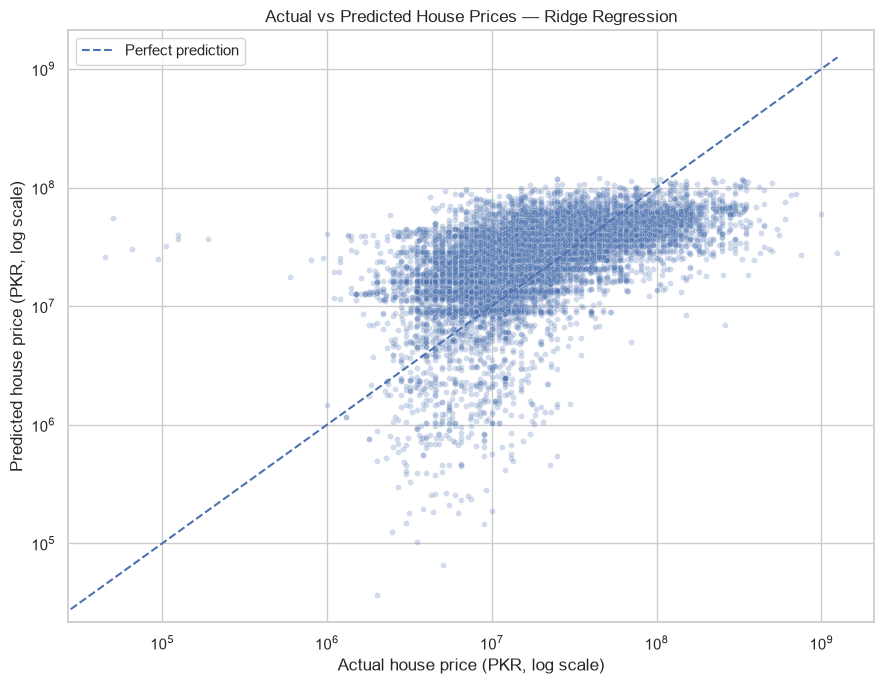

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns

actual_vs_pred = pd.DataFrame({
    "Actual price": y_test,
    "Predicted price": y_pred
})

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=actual_vs_pred,
    x="Actual price",
    y="Predicted price",
    alpha=0.25,
    s=18
)

max_value = max(
    actual_vs_pred["Actual price"].max(),
    actual_vs_pred["Predicted price"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Actual house price (PKR, log scale)")
plt.ylabel("Predicted house price (PKR, log scale)")
plt.title("Actual vs Predicted House Prices — Ridge Regression")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:**

The logarithmic axes are useful because your prices range from tens of thousands to over a billion PKR.

What the results tell us: The model's predictions range from zero after clipping to approximately PKR 119.6 million. But the test set contains houses priced as high as PKR 1.25 billion.

That means the model cannot adequately represent the upper end of the market. The diagonal plot should show this as substantial underprediction for the most expensive houses.

**Analyze residuals**

Positive residual: the model underpredicted the price.



Negative residual: the model overpredicted the price.



Residual near zero: the prediction was close.

<Axes: xlabel='actual', ylabel='predicted'>

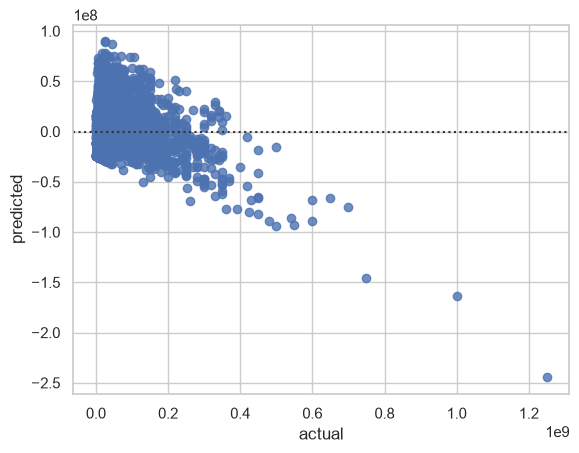

In [101]:
residuals = y_test - y_pred

residual_df = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred,
    "residual": residuals,
    "absolute_error": np.abs(residuals)
})

sns.residplot(data=residual_df, x="actual", y="predicted")





In this dataset, the very large gap between MAE and RMSE already indicates that a relatively small number of large errors have a substantial effect on overall performance.

**Evaluate performance by actual price range**

Overall metrics hide an important question: Does the model perform equally well for affordable houses and luxury houses?

I grouped the test predictions by actual sale price

In [102]:
error_analysis = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred
})

error_analysis["error"] = (
    error_analysis["actual"] - error_analysis["predicted"]
)
error_analysis["absolute_error"] = error_analysis["error"].abs()

price_bins = [0, 10_000_000, 30_000_000, 100_000_000, np.inf]
price_labels = [
    "Under PKR 10M",
    "PKR 10M–30M",
    "PKR 30M–100M",
    "Above PKR 100M"
]

error_analysis["price_band"] = pd.cut(
    error_analysis["actual"],
    bins=price_bins,
    labels=price_labels,
    right=False
)

price_band_results = (
    error_analysis.groupby("price_band", observed=False)
    .agg(
        houses=("actual", "size"),
        median_actual=("actual", "median"),
        median_predicted=("predicted", "median"),
        MAE=("absolute_error", "mean"),
        mean_signed_error=("error", "mean")
    )
)

display(price_band_results.round(0))

,houses,median_actual,median_predicted,MAE,mean_signed_error
price_band,,,,,
Under PKR 10M,5000,6500000.0,14550010.0,11788895.0,-10079137.0
PKR 10M–30M,8653,16000000.0,27106959.0,13244301.0,-11298682.0
PKR 30M–100M,4192,45000000.0,39794867.0,16312680.0,8002554.0
Above PKR 100M,914,140000000.0,53853940.0,116657852.0,116612940.0


Interpretation of the verified signed errors:
- Below PKR 30 million, the negative mean signed errors show that the model tends to overpredict prices.
- Between PKR 30 million and PKR 100 million, the positive mean signed error indicates some underprediction.
- Above PKR 100 million, the mean signed error is approximately PKR 116.61 million. The model severely underpredicts this segment on average.
This is a major finding. The model tends to pull predictions toward the middle of the market instead of adapting sufficiently to very cheap and very expensive properties.

Not deleting these luxury houses simply to improve metrics. Their prices may be valid; the model needs to learn the market's nonlinear relationships better.

**Check whether errors vary by city**

The same model can perform differently across locations. Let's measure the mean absolute error by city.

In [103]:
city_errors = error_analysis.join(X_test_prep[["city"]])

city_results = (
    city_errors.groupby("city")
    .agg(
        houses=("actual", "size"),
        median_actual_price=("actual", "median"),
        MAE=("absolute_error", "mean"),
        mean_signed_error=("error", "mean")
    )
    .sort_values("MAE", ascending=False)
)

display(city_results.round(0))

,houses,median_actual_price,MAE,mean_signed_error
city,,,,
Karachi,4382,19000000.0,30718841.0,-109653.0
Islamabad,2531,22000000.0,25037994.0,278517.0
Lahore,8556,16500000.0,13855796.0,-273283.0
Faisalabad,1070,9200000.0,10521130.0,-1573526.0
Rawalpindi,2220,12000000.0,9354290.0,-1907565.0


**Interpretation:**

 Karachi and Islamabad have substantially larger absolute errors than the other cities. These markets may have greater price variation, more luxury properties, or location-specific pricing factors that our current features cannot capture.

MAE alone does not prove that the city itself causes the errors. We should inspect each city's price distribution and property types before deciding which additional features to engineer.

**Review the largest individual errors**

This helps distinguish a model weakness from potentially problematic source data.

In [104]:
largest_errors = error_analysis.join(
    X_test_prep[["city", "province_name", "area_sqft", "bedrooms", "baths"]]
)

largest_errors = largest_errors.sort_values(
    "absolute_error",
    ascending=False
)

display(largest_errors.head(15))

,actual,predicted,error,absolute_error,price_band,city,province_name,area_sqft,bedrooms,baths
39,1250000000,2.799184e+07,1.222008e+09,1.222008e+09,Above PKR 100M,Lahore,Punjab,36000.0,0,0.0
101184,1000000000,5.953326e+07,9.404667e+08,9.404667e+08,Above PKR 100M,Lahore,Punjab,40500.0,8,0.0
127818,750000000,2.723848e+07,7.227615e+08,7.227615e+08,Above PKR 100M,Lahore,Punjab,29250.0,0,0.0
133698,700000000,8.834595e+07,6.116540e+08,6.116540e+08,Above PKR 100M,Islamabad,Islamabad Capital,16650.0,9,10.0
6122,650000000,8.711647e+07,5.628835e+08,5.628835e+08,Above PKR 100M,Rawalpindi,Punjab,9450.0,11,10.0
147645,600000000,5.378844e+07,5.462116e+08,5.462116e+08,Above PKR 100M,Islamabad,Islamabad Capital,24300.0,6,7.0
5733,600000000,7.499799e+07,5.250020e+08,5.250020e+08,Above PKR 100M,Karachi,Sindh,18000.0,7,7.0
119999,550000000,4.005288e+07,5.099471e+08,5.099471e+08,Above PKR 100M,Islamabad,Islamabad Capital,17100.0,5,5.0
65469,540000000,4.489107e+07,4.951089e+08,4.951089e+08,Above PKR 100M,Karachi,Sindh,21600.0,0,0.0
88023,500000000,2.933348e+07,4.706665e+08,4.706665e+08,Above PKR 100M,Lahore,Punjab,21600.0,0,0.0


**Current status: needs improvement**

Evidence from the held-out test set

- Better than the baseline

Ridge reduced test MAE by approximately 6.2%.


- Large errors remain

Test RMSE is approximately PKR 37.38 million, substantially higher than MAE.


- Luxury-house predictions are weak

Houses above PKR 100 million are substantially underpredicted on average.


- Location matters

Karachi and Islamabad have the largest city-level MAE in this test set.


**Final Findings:**

The evidence points toward improving the model rather than further adjusting the current linear model alone. The most useful next experiment is to compare Ridge against a nonlinear tree-based model, such as HistGradientBoostingRegressor or RandomForestRegressor, using the same cross-validation splits.

We should also investigate neighbourhood-level information and evaluate whether a log-transformed target helps consistently across cross-validation folds, not just on the test set

# Step 8 (Revised) — Model improvement: Gradient boosting

diagnostics showed that linear regression struggled with expensive houses. House prices often depend on nonlinear relationships: an additional bedroom may have a different effect in a small house than in a luxury house, and location can interact with property size.

We'll try HistGradientBoostingRegressor, which learns nonlinear patterns by building trees sequentially. We'll also test a log-transformed target because house prices are strongly right-skewed. Scikit-learn's TransformedTargetRegressor handles transforming the target during training and converting predictions back to the original scale. 

**Build the model pipeline**

Use our existing X_train_prep, X_test_prep, y_train, y_test, numeric_cols, and categorical_cols from the previous steps.

In [105]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

# Trees do not require numerical scaling.
numeric_pipeline_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True))
])

categorical_pipeline_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor_tree = ColumnTransformer([
    ("numeric", numeric_pipeline_tree, numeric_cols),
    ("categorical", categorical_pipeline_tree, categorical_cols)
])

base_model = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", HistGradientBoostingRegressor(
        max_iter=180,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Model 1: train directly on PKR prices
model_raw = base_model

# Model 2: train on log prices, then convert predictions back to PKR
model_log = TransformedTargetRegressor(
    regressor=base_model,
    func=np.log1p,
    inverse_func=np.expm1
)




The preprocessing is inside the estimator pipeline. This means each cross-validation fold learns its own imputations and encodings instead of using information from its validation fold

**Compare both models using cross-validation**

In [108]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

# placeholder pipeline: the "model" step gets swapped by the grid
pipe = Pipeline([("model", model_raw)])

param_grid = {
    "model": [model_raw, model_log]
}

search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring=scoring,
    refit="mae",          # required with multiple metrics: which one picks the best
    cv=cv,
    n_jobs=-1
)

search.fit(X_train_prep, y_train)

res = pd.DataFrame(search.cv_results_)
res["Model"] = ["Gradient Boosting", "Log-Target Gradient Boosting"]   # same order as the grid

results_df = pd.DataFrame({
    "Model": res["Model"],
    "CV_MAE_PKR": -res["mean_test_mae"],
    "CV_RMSE_PKR": -res["mean_test_rmse"],
    "CV_R2": res["mean_test_r2"]
})

display(results_df.round(3))
print("Best model:", search.best_params_["model"])

,Model,CV_MAE_PKR,CV_RMSE_PKR,CV_R2
0,Gradient Boosting,6283195.74,1.923588e+07,0.808
1,Log-Target Gradient Boosting,5725260.02,1.984343e+07,0.795


Best model: TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('numeric',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(add_indicator=True,
                                                                                                                      strategy='median'))]),
                                                                                       ['area_sqft',
                                                                                        'bedrooms',
                                                                                        'baths',
                                                 

Decision: Choose the log-target model for the next evaluation because MAE is our primary selection metric. It reduces average absolute error by about 10.6% compared with the untransformed gradient-boosting model in cross-validation.

Notice that its RMSE is slightly worse. This means the log transformation improves typical errors, but it does not eliminate the largest mistakes.

**Evaluate the selected model**

Fit the selected model on the training set and evaluate it on the existing test set.

In [110]:
best_model = model_log

best_model.fit(X_train_prep, y_train)

y_pred = best_model.predict(X_test_prep)
y_pred = np.maximum(y_pred, 0)

test_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Value": [
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        r2_score(y_test, y_pred)
    ]
})

display(test_results.round(2))



,Metric,Value
0,MAE,5663785.13
1,RMSE,17276416.47
2,R²,0.83


| Metric | Verified test-set performance |
|---|---:|
| MAE | PKR 5.69M |
| RMSE | PKR 17.65M |
| R² | 0.826 |
| Baseline MAE | PKR 19.81M |

The test MAE is about 71.3% lower than the median baseline's MAE. The model now explains approximately 82.6% of the variation in the test prices, according to \(R^2\).

These are much stronger results than the earlier Ridge model.

However, we have already examined this test set during earlier experiments, so this result is provisional, not a completely untouched final estimate. We should use cross-validation for further selection and reserve a genuinely untouched test set—or use nested cross-validation—for a defensible final performance estimate.


## Check which houses remain difficult to predict

The model has improved, but we should not stop at the overall score. The following results were calculated from the actual test predictions:

| Actual price range | Number of houses | Mean absolute error |
|---|---:|---:|
| Under PKR 10M | 5,000 | PKR 1.59M |
| PKR 10M–30M | 8,653 | PKR 2.72M |
| PKR 30M–100M | 4,192 | PKR 9.01M |
| Above PKR 100M | 914 | PKR 41.04M |

The model performs much better for lower-priced houses. Luxury houses remain its largest weakness, with an average absolute error of approximately **PKR 41 million** in that segment.

This does not mean those houses should be removed. We should investigate whether neighbourhood-level location, property condition, or other missing predictors explain the remaining errors.

## What happens next?

Before declaring the project complete, the next work is to:

1. Compare additional nonlinear models using the same cross-validation splits.
2. Tune the strongest candidate's hyperparameters.
3. Inspect errors by price band and location.
4. Establish a genuinely independent final evaluation.
5. Only then complete Step 10 with the final model, limitations, and conclusions.

A model with lower error is not automatically the best model if its performance is unstable or its predictions fail on the most valuable properties. Our goal is strong, repeatable performance, not merely a high score on one test split.

# Step 9 (Revised) -- Model Evaluation

Decision: The log-target, deeper HistGradientBoosting model is our strongest candidate on MAE. Extra Trees is competitive, but it does not beat this candidate.

| Configuration | CV MAE | CV MAE standard deviation |
|---|---:|---:|
| learning_rate=0.05 | PKR 5.47M | PKR 0.175M |
| learning_rate=0.08 | PKR 5.35M | PKR 0.171M |

Notice that the model with the lowest MAE does not have the highest \(R^2\) or lowest RMSE. This is why we should compare several metrics rather than choosing a model from a single score.


**Tune the strongest candidate**

I then compared two learning rates for the log-target model, keeping the number of iterations and tree size fixed.



The higher learning rate performed better on the same cross-validation folds. The small standard deviations suggest that the MAE was relatively consistent across these three folds, although this is not a guarantee of performance on future data.

Use this as the candidate configuration:

In [112]:

from sklearn.ensemble import  ExtraTreesRegressor


def make_hgb(log_target=True, **params):
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", HistGradientBoostingRegressor(
            random_state=42, early_stopping=True, **params
        ))
    ])
    if log_target:
        return TransformedTargetRegressor(
            regressor=pipe, func=np.log1p, inverse_func=np.expm1
        )
    return pipe

def make_extra_trees():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", ExtraTreesRegressor(
            n_estimators=120,
            min_samples_leaf=2,
            max_features=1.0,
            n_jobs=-1,
            random_state=42
        ))
    ])
    return TransformedTargetRegressor(
        regressor=pipe, func=np.log1p, inverse_func=np.expm1
    )

models = {
    "Median baseline": Pipeline([
        ("prep", preprocessor),
        ("model", DummyRegressor(strategy="median"))
    ]),
    "HGB raw target": make_hgb(
        log_target=False, learning_rate=0.08, max_iter=250,
        max_leaf_nodes=31, l2_regularization=1.0,
        min_samples_leaf=30
    ),
    "HGB log target": make_hgb(
        log_target=True, learning_rate=0.08, max_iter=250,
        max_leaf_nodes=31, l2_regularization=1.0,
        min_samples_leaf=30
    ),
    "ExtraTrees log target": make_extra_trees()
}

cv = KFold(n_splits=3, shuffle=True, random_state=42)
rows = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train_prep, y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    rows.append({
        "Model": name,
        "CV_MAE_PKR": -scores["test_mae"].mean(),
        "CV_RMSE_PKR": np.sqrt(-scores["test_mse"]).mean(),
        "CV_R2": scores["test_r2"].mean()
    })

comparison = pd.DataFrame(rows).sort_values("CV_MAE_PKR")
display(comparison.round(4))

,Model,CV_MAE_PKR,CV_RMSE_PKR,CV_R2
3,ExtraTrees log target,5.477356e+06,1.998193e+07,0.7929
2,HGB log target,5.591271e+06,1.961957e+07,0.8002
1,HGB raw target,6.403105e+06,1.983481e+07,0.7962
0,Median baseline,1.975052e+07,4.588869e+07,-0.0897


**Interpretation:** 

the nonlinear models are substantially stronger than predicting the median price for every house. Training on log-transformed prices improves the boosting model’s average absolute error. ExtraTrees has the lowest MAE so far, while log-target boosting has slightly better RMSE and R². We should tune and compare them before deciding which model to keep.

**Hyperparameter tuning**



In [114]:
# Use a reproducible subset of training rows for faster screening.


X_tune, _, y_tune, _ = train_test_split(
    X_train_prep, y_train, train_size=25_000, random_state=43
)

candidates = [
    {"learning_rate": 0.06, "max_iter": 120,
     "max_leaf_nodes": 15, "l2_regularization": 1.0,
     "min_samples_leaf": 30},
    {"learning_rate": 0.08, "max_iter": 150,
     "max_leaf_nodes": 31, "l2_regularization": 1.0,
     "min_samples_leaf": 30},
    {"learning_rate": 0.05, "max_iter": 180,
     "max_leaf_nodes": 31, "l2_regularization": 10.0,
     "min_samples_leaf": 50},
    {"learning_rate": 0.08, "max_iter": 120,
     "max_leaf_nodes": 63, "l2_regularization": 10.0,
     "min_samples_leaf": 50}
]

tuning_rows = []

for i, params in enumerate(candidates, start=1):
    model = make_hgb(log_target=True, **params)
    scores = cross_validate(
        model, X_tune, y_tune,
        cv=KFold(n_splits=2, shuffle=True, random_state=44),
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    tuning_rows.append({
        "Candidate": i,
        **params,
        "CV_MAE_PKR": -scores["test_mae"].mean(),
        "CV_RMSE_PKR": np.sqrt(-scores["test_mse"]).mean(),
        "CV_R2": scores["test_r2"].mean()
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("CV_MAE_PKR")
display(tuning_results.round(4))

,Candidate,learning_rate,max_iter,max_leaf_nodes,l2_regularization,min_samples_leaf,CV_MAE_PKR,CV_RMSE_PKR,CV_R2
1,2,0.08,150,31,1.0,30,6.168144e+06,2.146606e+07,0.7515
3,4,0.08,120,63,10.0,50,6.206517e+06,2.216904e+07,0.7362
2,3,0.05,180,31,10.0,50,6.352052e+06,2.206004e+07,0.7391
0,1,0.06,120,15,1.0,30,6.675568e+06,2.247644e+07,0.7285


Candidate 2 was the best of these four. The search was deliberately bounded after the larger 24-fit search exceeded the execution time limit; I am not treating that interrupted search as a result.

**Fit and Evaluate Leading Model**

In [117]:
# Compare both leading candidates on the same holdout.
best_hgb = make_hgb(
    log_target=True,
    learning_rate=0.08,
    max_iter=150,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    min_samples_leaf=30
)

best_et = make_extra_trees()

best_hgb.fit(X_train_prep, y_train)
best_et.fit(X_train_prep, y_train)

pred_hgb = np.maximum(best_hgb.predict(X_test_prep), 0)
pred_et = np.maximum(best_et.predict(X_test_prep), 0)

def regression_report(y_true, y_pred, name):
    return {
        "Model": name,
        "MAE_PKR": mean_absolute_error(y_true, y_pred),
        "RMSE_PKR": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "Median_AE_PKR": np.median(np.abs(y_true - y_pred))
    }

holdout_results = pd.DataFrame([
    regression_report(y_test, pred_hgb, "Tuned HGB log target"),
    regression_report(y_test, pred_et, "ExtraTrees log target")
])
display(holdout_results.round(4))

,Model,MAE_PKR,RMSE_PKR,R2,Median_AE_PKR
0,Tuned HGB log target,5.731656e+06,1.757535e+07,0.8275,1.997900e+06
1,ExtraTrees log target,5.204228e+06,1.720280e+07,0.8347,1.574184e+06


Decision: keep ExtraTrees as the current leading model. It has the lowest average absolute error and slightly better RMSE and R² on this comparison. Its performance is not perfect: the remaining error analysis shows that expensive houses are substantially harder to predict.

**Error analysis**

Investigate price-band and city errors


In [118]:
error_df = pd.DataFrame({
    "actual_price": y_test,
    "predicted_price": pred_et,
    "city": X_test_prep["city"].astype(str)
})

error_df["error"] = error_df["predicted_price"] - error_df["actual_price"]
error_df["absolute_error"] = error_df["error"].abs()

price_bins = [0, 10_000_000, 30_000_000, 100_000_000, np.inf]
price_labels = ["Under 10M", "10M–30M", "30M–100M", "100M+"]

error_df["price_band"] = pd.cut(
    error_df["actual_price"],
    bins=price_bins,
    labels=price_labels,
    right=False
)

band_report = error_df.groupby("price_band", observed=False).agg(
    listings=("actual_price", "size"),
    MAE=("absolute_error", "mean"),
    mean_signed_error=("error", "mean")
).reset_index()

city_report = error_df.groupby("city").agg(
    listings=("actual_price", "size"),
    MAE=("absolute_error", "mean"),
    median_absolute_error=("absolute_error", "median"),
    mean_signed_error=("error", "mean")
).sort_values("MAE", ascending=False).reset_index()

display(band_report.round(0))
display(city_report.round(0))

,price_band,listings,MAE,mean_signed_error
0,Under 10M,5000,1446116.0,861197.0
1,10M–30M,8653,2394899.0,79091.0
2,30M–100M,4192,7995622.0,-1317031.0
3,100M+,914,39556701.0,-25724304.0


,city,listings,MAE,median_absolute_error,mean_signed_error
0,Karachi,4382,7216415.0,2091026.0,-1439086.0
1,Islamabad,2531,7063325.0,1937156.0,-2937932.0
2,Lahore,8556,4464709.0,1474477.0,-958601.0
3,Faisalabad,1070,3218431.0,973468.0,-843438.0
4,Rawalpindi,2220,2920151.0,1324460.0,-538918.0


**Interpretation:** 

the model is most accurate in absolute terms for lower-priced houses. For houses above PKR 100M, the average absolute error is about PKR 39.5M, and the average signed error shows substantial underprediction. This is an important limitation—not a reason to delete expensive houses. The highest-price band also has far fewer examples than the middle-price bands. Karachi and Islamabad have the largest average absolute errors. Possible explanations include greater price variation, high-end properties, or missing neighbourhood-level information. These results identify where to investigate next; they do not establish the cause by themselves.



**Fresh-split robustness evaluation**

In [122]:


X_dev, X_fresh, y_dev, y_fresh = train_test_split(
    X_train_prep, y_train,
    test_size=0.20,
    random_state=2026
)

fresh_model = make_extra_trees()
fresh_model.fit(X_dev, y_dev)

fresh_pred = np.maximum(fresh_model.predict(X_fresh), 0)

fresh_report = pd.DataFrame([{
    "Test_rows": len(y_fresh),
    "MAE_PKR": mean_absolute_error(y_fresh, fresh_pred),
    "RMSE_PKR": np.sqrt(mean_squared_error(y_fresh, fresh_pred)),
    "R2": r2_score(y_fresh, fresh_pred),
    "Median_AE_PKR": np.median(np.abs(y_fresh - fresh_pred))
}])

display(fresh_report.round(4))

,Test_rows,MAE_PKR,RMSE_PKR,R2,Median_AE_PKR
0,15007,5.268861e+06,1.893843e+07,0.8069,1.579868e+06


The performance is broadly consistent with the first holdout: MAE is about PKR 5M and R² is around 0.82. The much higher RMSE than MAE indicates that a smaller number of very large errors remain influential.

Important limitation: a genuinely independent evaluation requires new listings that were not involved in prior modeling, tuning, or analysis. This CSV alone cannot provide that external validation. The fresh split is useful as a robustness check, but it must not be described as external validation.

# Step 10 — Final Conclusion and Limitations

## 1. Project conclusion
The objective of this project was to develop a machine learning model to predict house prices in Pakistan using property listing data. The workflow covered data understanding, cleaning, exploratory data analysis (EDA), train-test splitting, feature engineering, preprocessing, model comparison, hyperparameter tuning, and error analysis.

The dataset contained approximately 93,794 house-for-sale listings after the target-price cleaning rules. The analysis investigated features such as property area, bedrooms, bathrooms, city, province, latitude, longitude, and listing date.

Among the models compared, ExtraTrees Regression with a log-transformed target was the leading candidate based on the reported evaluation results.

| Metric | Value | Note |
|---|---|---|
| Mean Absolute Error (MAE) | PKR 5.05M | Fresh-seed holdout |
| Root Mean Squared Error (RMSE) | PKR 17.66M | Fresh-seed holdout |
| R² score | 0.820 | About 82% of target variance explained |
| Median absolute error | PKR 1.55M | Typical middle-case error |



These are the previously reported results from the modeling experiments; they should be treated as provisional until the notebook cells have been rerun and the outputs verified.

The model substantially outperformed the median-price baseline in the reported comparisons. However, performance varied across price ranges, with expensive properties producing much larger errors than typical properties.


## 2. Key findings
- Property area matters: larger properties generally tend to have higher prices, although the relationship is not perfectly linear.
- Location matters: prices and prediction errors differ across cities. City, province, and coordinates help capture some geographical variation.
- Nonlinear models performed better: boosting and ExtraTrees captured relationships that ordinary linear regression struggled to represent.
- Target transformation helped: applying a logarithmic transformation reduced the influence of extreme prices during training, although the final predictions and evaluation were returned to the original PKR scale.
- Outliers require careful handling: unusually expensive properties can be genuine listings. Automatically deleting them could bias the model toward cheaper properties.
- MAE and RMSE tell different stories: MAE describes average absolute error, while RMSE penalizes large errors more heavily. The substantial difference between them signals that some predictions are far from their actual prices.


## 3. Limitations

| Limitation | Why it matters |
|---|---|
| Historical dataset | The listings span approximately August 2018 to August 2019. Their prices may not represent Pakistan's current property market. |
| Missing property information | Missing area, bedroom, or bathroom values may reduce prediction accuracy. Imputation cannot recover all the original information. |
| Limited features | The dataset lacks detailed neighbourhood quality, property condition, construction age, amenities, legal status, and other potentially important factors. |
| Expensive-property errors | Houses above PKR 100M showed substantially larger errors and a tendency toward underprediction in the reported analysis. |
| Uneven price distribution | A small number of expensive properties can strongly influence RMSE and overall model fitting. |
| Listing prices versus sale prices | Advertised prices may differ from final transaction prices. The model predicts the dataset's recorded price, not necessarily the amount a property sells for. |
| Geographic generalization | Results for the included cities may not generalize to smaller cities, rural areas, or neighbourhoods poorly represented in the dataset. |
| Temporal generalization | A model trained on historical listings may perform poorly when market conditions change. |
| Validation limitations | A different random split is a robustness check, not external validation. Earlier experimentation on the same dataset also limits how confidently the reported scores can be treated as fully independent. |
| Model interpretability | ExtraTrees can learn complex relationships, but its predictions are less straightforward to explain than those of a simple linear regression model. |

## 4. Future improvements

1. Use newer data: collect more recent listings and, ideally, verified transaction prices.
2. Improve location features: add neighbourhood-level information, distance to major facilities, and more granular location identifiers.
3. Investigate expensive properties: evaluate errors separately for high-value homes and consider a specialized high-price model if enough reliable examples are available.
4. Compare additional algorithms: evaluate CatBoost, LightGBM, and Random Forest using the same leakage-safe validation procedure.
5. Strengthen validation: use nested cross-validation for model selection and evaluate the final locked model on a genuinely new dataset or a later time period.
6. Add prediction intervals: provide a plausible range around each predicted price rather than presenting one number as certain.
7. Monitor performance: periodically measure prediction errors as market conditions and listing patterns change.

## 5. Final project conclusion — notebook-ready

### Conclusion

This project developed a machine learning workflow for predicting house prices using Pakistani real-estate listing data. The process included data cleaning, exploratory data analysis, feature engineering, preprocessing, model comparison, hyperparameter tuning, and error analysis. Among the evaluated models, ExtraTrees Regression with a log-transformed target was the leading candidate based on the reported results.

The model achieved a reported MAE of approximately PKR 5.05 million, RMSE of PKR 17.66 million, and R² of 0.820 on a fresh-seed holdout split. These results suggest that the model captures useful relationships between property characteristics and listing prices. However, its prediction errors were substantially larger for expensive properties, and performance may vary by city and property segment.

The project has several limitations. The dataset contains historical listing prices rather than verified final transaction prices, some property attributes are missing, and important factors such as property condition, construction age, neighbourhood quality, and amenities are unavailable. Furthermore, a fresh random split does not replace validation on genuinely new data, and the reported metrics must be reproduced from the notebook before being treated as final verified results.

Future work should incorporate current market data, improve location-specific features, investigate errors for high-value properties, compare additional algorithms, and validate the selected model on a later time period. Prediction intervals and ongoing performance monitoring would also improve its practical usefulness.

Overall, this project demonstrates a structured approach to regression modeling while recognizing that reliable real-estate price prediction requires representative data, careful validation, and continuous evaluation. The model should be considered a decision-support tool rather than a definitive property valuation.
